# M02b · Variables aléatoires et lois usuelles — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/m02b_variables_aleatoires/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | M02b.1 à M02b.10, M02b.14 | Les exercices papier (vérification) | ✏️ 🔗 | | |
| A | M02b.18 | Lois binomiale et de Poisson · `binomial_pmf`, `poisson_pmf` | 🔨 | ★ | 20 |
|  | M02b.19 | Densité et fonction de répartition de la loi normale (avec `math.erf`) · `normal_pdf`, `normal_cdf` | 🔨 | ★ | 20 |
|  | M02b.20 | Simuler par inversion de la fonction de répartition · `inverse_transform_sample` | 🔨 | ★★ | 20 |
|  | M02b.21 | `scipy.stats` : pmf, pdf, cdf, ppf et rvs | 📦 | ★ | 15 |
| B | M02b.22 | Prédire : la variance de la moyenne de quatre dés | 🔮 | ★ | 10 |
|  | M02b.23 | Binomiale et Poisson côte à côte quand n grandit | 🔬 | ★★ | 20 |
|  | M02b.24 | Une loi jointe en carte de chaleur, ses marginales sur les bords | 🎨 | ★ | 20 |
| C | M02b.25 | Chasse à l'erreur : une densité prise pour une probabilité, σ et σ² | 🐛 | ★ | 15 |
|  | M02b.26 | Documenter une loi : docstring et exemples testés (`doctest`) | 🛠️ | ★ | 15 |
|  | M02b.27 | Défi : tirer des valeurs normales avec seulement des tirages uniformes | 🏆 | ★★★ | 30 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : lois binomiale, géométrique, de Poisson, uniforme, exponentielle et normale, espérances et variances, loi jointe et indépendance, variance d'une somme, intégrale double, changement de variable, erreurs d'annotation.
- Écrire les cinq fonctions de `mymath/distributions.py` et les tester, puis utiliser `scipy.stats`.
- Prédire la variance d'une moyenne, mesurer l'écart entre binomiale et Poisson, dessiner une loi jointe, chasser des confusions, documenter une loi, tirer des normales avec des uniformes.

**Rappel express.** $\mathcal{B}(n, p)$ : $\binom{n}{k}p^k(1-p)^{n-k}$, $\mathbb{E} = np$, $\mathbb{V} = np(1-p)$ ; $\mathcal{P}(\lambda)$ : $e^{-\lambda}\frac{\lambda^k}{k!}$, $\mathbb{E} = \mathbb{V} = \lambda$ ; $\mathcal{E}(\lambda)$ : $P(T > t) = e^{-\lambda t}$, $\mathbb{E} = \frac{1}{\lambda}$ ; $\mathcal{N}(\mu, \sigma^2)$ : $P(X \le x) = \Phi\big(\frac{x - \mu}{\sigma}\big)$. $\mathbb{V}(X + Y) = \mathbb{V}(X) + \mathbb{V}(Y)$ si $X$ et $Y$ sont indépendantes. Inversion : $F^{-1}(U)$ suit la loi de $F$.

## Partie 0 · Vérifier tes exercices papier (✏️ M02b.1 à M02b.10, 🔗 M02b.14)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un entier, ou un nombre avec un point décimal, `-1.25`, arrondi comme le demande la question ;
- une fraction irréductible entre guillemets, `"5/9"` ;
- une expression entre guillemets, dans la variable indiquée ($p$, $x$ ou $y$), avec `**` pour les puissances, `sqrt` et des parenthèses autour d'un dénominateur, `"3/(2*p)"`, `"sqrt(y)/5"` ;
- une liste `[0.25, 0.75]`, un intervalle `"[-2 ; 7]"`, ou `True` / `False`.

Pour la loi normale, utilise la table de $\Phi$ de la fiche (§3) : les réponses attendues sont arrondies de sorte que la table et un calcul exact donnent la même valeur. Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed exactly from the statements (Φ: the values of the table, fiche §3)
import math
from fractions import Fraction

**Ex M02b.1 — Loi de Bernoulli et loi binomiale**

In [3]:
wbm.record("M02b.1a", 0.8 ** 5, decimals=4, mistakes={"0,8 est la probabilité de réussir un lancer : cinq réussites, c'est 0,8 à la puissance 5": 0.2 ** 5, "les cinq lancers réussissent tous : les probabilités se multiplient, elles ne s'additionnent pas": 4.0})
wbm.record("M02b.1b", math.comb(5, 3) * 0.8 ** 3 * 0.2 ** 2, decimals=4, mistakes={"n'oublie pas C(5, 3) : le nombre de façons de placer les 3 réussites parmi les 5 lancers": 0.8 ** 3 * 0.2 ** 2, "p^k (1 − p)^(n − k) : la probabilité de réussite porte l'exposant k, le nombre de réussites": math.comb(5, 3) * 0.8 ** 2 * 0.2 ** 3})
wbm.record("M02b.1c", math.comb(5, 4) * 0.8 ** 4 * 0.2 + 0.8 ** 5, decimals=4, mistakes={"X ≥ 4 : X = 4 ou X = 5, additionne les deux probabilités": {math.comb(5, 4) * 0.8 ** 4 * 0.2, 0.8 ** 5}, "c'est P(X ≤ 3) ; X ≥ 4 est l'événement contraire": 1 - math.comb(5, 4) * 0.8 ** 4 * 0.2 - 0.8 ** 5})
wbm.record("M02b.1d", 4, mistakes={"compare P(X = 4) et P(X = 5) : la valeur la plus probable n'est pas forcément n": 5})
wbm.record("M02b.1e", 5 * 0.8, decimals=1, mistakes={"E[X] = n p pour la loi binomiale B(n, p) : n essais, chacun réussi en moyenne p fois": 0.8, "c'est l'espérance du nombre d'échecs ; E[X] = n p, avec p la probabilité de réussite": 1.0})
wbm.record("M02b.1f", 5 * 0.8 * 0.2, decimals=2, mistakes={"c'est l'espérance ; la variance de B(n, p) vaut n p (1 − p)": 4.0, "c'est la variance d'un seul lancer ; pour 5 lancers indépendants, les variances s'additionnent": 0.16, "c'est l'écart-type ; la variance est son carré": 0.894})
wbm.record("M02b.1g", 1 - 0.8 ** 5, decimals=4, mistakes={"c'est P(aucun échec) ; « au moins un échec » est l'événement contraire": 0.8 ** 5, "« au moins un échec » est le contraire de « cinq réussites », pas de « cinq échecs »": 1 - 0.2 ** 5})
wbm.record("M02b.1h", 11, mistakes={"1 − 0,8ⁿ ≥ 0,9 équivaut à 0,8ⁿ ≤ 0,1 : avec ce n, 0,8ⁿ dépasse encore 0,1": 10, "le plus petit n qui convient : vérifie aussi l'entier juste en dessous": 12})

WBM_ANSWER {"coarse_any": {"1": ["be38d1c625ec822fbfe0768c82c5d552aee3f0fab4ebe73a50e0038fa0a374fa"]}, "coarser": {"2": ["6b1db1cf75b72ba5a7e050e88bb818b07ddbdab180423d916cb94f8981eb2cc6"]}, "decimals": 4, "hash": "faf25e629f03f2beaa957b7936d18ed30d70891a9a4bc5db890be6ef6617bfac", "hash_coarse": "792658bb06fefe077dd216dade7ce05cc6c3547302337e3b0671ad583da63dfe", "id": "M02b.1a", "kind": "float", "magnitude": -1, "mistakes": {"5a6cb77f4f85cb4beb39f09d8e49198502139383ac61511b0527f14bf5042667": "les cinq lancers réussissent tous : les probabilités se multiplient, elles ne s'additionnent pas", "95ca81270d087ae6e745d25412e5d8778f34427e060181e18d80d51cd9be2a45": "0,8 est la probabilité de réussir un lancer : cinq réussites, c'est 0,8 à la puissance 5"}, "sign": 1}
📝 Ex M02b.1a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"1": ["304c01e6bb9c46a60f0909ad49b96e54e4d4370b4ee5b6bfdc94086413486d69"]}, "coarser": {"2": ["4c86ecdaaf39d193df61e8fc36340dfd85860cca051b6e4cc653

**Ex M02b.2 — Loi géométrique : probabilités, et l'espérance par une série**

In [4]:
wbm.record("M02b.2a", 0.6 ** 2 * 0.4, decimals=3, mistakes={"X = 3 : deux échecs (probabilité 0,6 chacun), puis une réussite (0,4)": {0.4 ** 2 * 0.6, 0.4 ** 3}})
wbm.record("M02b.2b", 0.6 ** 3, decimals=3, mistakes={"X > 3 : les trois premières tentatives échouent, chacune avec la probabilité 0,6, et rien n'est imposé à la quatrième": {0.4 ** 3, 0.6 ** 4}, "c'est P(X ≤ 3) ; P(X > 3) est l'événement contraire": 1 - 0.6 ** 3})
wbm.record("M02b.2c", 1 - 0.6 ** 2, decimals=2, mistakes={"X ≤ 2 : réussite à la première tentative ou à la deuxième, additionne les deux cas": {0.4, 0.24}})
wbm.record("M02b.2d", 1 / (1 - 0.6) ** 2, decimals=2, mistakes={"S − qS est la série géométrique Σ q^(k−1), de somme 1/(1 − q) ; S s'obtient en divisant encore par 1 − q": 1 / (1 - 0.6), "S = 1/(1 − q)², sans facteur q au numérateur": 0.6 / (1 - 0.6) ** 2})
wbm.record("M02b.2e", 0.4 / (1 - 0.6) ** 2, decimals=1, mistakes={"E[X] = Σ k p q^(k−1) = p × S : n'oublie pas le facteur p": 1 / (1 - 0.6) ** 2, "c'est q/p, le nombre moyen d'échecs ; X compte aussi la tentative réussie": 0.6 / 0.4, "E[X] = p × S, avec la somme S de d)": 1 / 0.6})
wbm.record("M02b.2f", 0.6 / 0.4, decimals=1, mistakes={"les tentatives échouées sont X − 1 : toutes sauf la dernière": 0.4 / (1 - 0.6) ** 2})
wbm.record("M02b.2g", 2, mistakes={"P(X ≤ 1) = 0,4 n'atteint pas 0,5 : la médiane est plus loin": 1, "le plus petit k : P(X ≤ 2) atteint déjà 0,5": 3})
wbm.record("M02b.2h", "1/p", kind="expr", variables=("p",), mistakes={"c'est le nombre moyen d'échecs ; X compte aussi la tentative réussie": "(1 - p)/p", "1 − q = p : p × 1/(1 − q)² se simplifie en divisant par p": "1/(1 - p)", "n'oublie pas le facteur p devant la somme S": "1/p**2"})

WBM_ANSWER {"coarse_any": {"1": ["28007f5268c0254e448aade982a34e93e9474b2fb5bc2e8333458413270f38c0"]}, "decimals": 3, "hash": "ad2f0b41c3c7c6160f1bbe3dfbd713eaac316930610d63ef584d74865f4b68ef", "hash_coarse": "52ee05a6153f868d23a88e8309f18acefb321a2e8e7f141251617f0b190302b5", "id": "M02b.2a", "kind": "float", "magnitude": -1, "mistakes": {"29fe186a3e82b32b2d291cde048839d56bdf93fadb90414bae8942bb4b237834": "X = 3 : deux échecs (probabilité 0,6 chacun), puis une réussite (0,4)", "6fa4032fcda95afa1f11855674bb5bb1b9e6fb3a59dbf721095c8dc13f9dab03": "X = 3 : deux échecs (probabilité 0,6 chacun), puis une réussite (0,4)"}, "sign": 1}
📝 Ex M02b.2a : réponse enregistrée (float, 3 décimales).
WBM_ANSWER {"coarse_any": {"1": ["69504c1289766ca6eb583203bb8b1443d36b1f2982531d9d7c2e43673f19e69d"]}, "decimals": 3, "hash": "daea2e0f9884fa6d54bd7cb31623fb8698b45a50c387a67495bd5bd80c3ea0a3", "hash_coarse": "6c8e974ae65749ff3a2457803db8cb9da49d0f627efc6c5e12daf9dbf1154b2d", "id": "M02b.2b", "kind": "float

WBM_ANSWER {"hash": "5df148ef14d9853943fc96362f3780ff93be98d0d71266d59532afbf9521b2a6", "id": "M02b.2h", "kind": "expr", "mistakes": {"5645497d8e3c9afaa13cdb2ff802898ba0d7dc10a1bfc89e483a40b96071e06c": "c'est le nombre moyen d'échecs ; X compte aussi la tentative réussie", "6fba697d95c460a4d249f0823de41f0c011c16c88bb061d9769c987129df7c08": "n'oublie pas le facteur p devant la somme S", "bbc0d9ea75a77943d06f1cfcfde8d8d93a499de6e0599b85dca89cda539f31fc": "1 − q = p : p × 1/(1 − q)² se simplifie en divisant par p"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["p"]}
📝 Ex M02b.2h : réponse enregistrée (expr).


**Ex M02b.3 — Loi de Poisson : probabilités, espérance, et la somme de deux variables de Poisson indépendantes**

In [5]:
wbm.record("M02b.3a", math.exp(-1.5), decimals=4, mistakes={"c'est P(X ≥ 1) ; P(X = 0) = e^(−λ) λ⁰/0! = e^(−λ)": 1 - math.exp(-1.5)})
wbm.record("M02b.3b", math.exp(-1.5) * 1.5 ** 2 / 2, decimals=4, mistakes={"λᵏ/k! avec k = 2 : n'oublie pas de diviser par 2! = 2": math.exp(-1.5) * 1.5 ** 2, "λᵏ/k! avec k = 2 : λ au carré, divisé par 2": math.exp(-1.5) * 1.5})
wbm.record("M02b.3c", 1 - math.exp(-1.5) * (1 + 1.5), decimals=4, mistakes={"X ≥ 2 exclut X = 0 et X = 1 : retire les deux probabilités": 1 - math.exp(-1.5), "c'est P(X ≤ 1) ; X ≥ 2 est l'événement contraire": math.exp(-1.5) * 2.5})
wbm.record("M02b.3d", 5 * 1.5, decimals=1, mistakes={"sur 5 jours, la linéarité de l'espérance additionne l'espérance de chaque jour": 1.5})
wbm.record("M02b.3e", math.exp(-1.5) * math.exp(-2.5), decimals=4, mistakes={"S = 0 demande X = 0 et Y = 0 : pour des variables indépendantes, les probabilités se multiplient": math.exp(-1.5) + math.exp(-2.5)})
wbm.record("M02b.3f", math.exp(-4) * (2.5 + 1.5), decimals=4, mistakes={"S = 1 : (X, Y) vaut (0, 1) ou (1, 0) ; additionne les deux cas": {math.exp(-4) * 2.5, math.exp(-4) * 1.5}, "(X, Y) = (1, 1) donne S = 2, pas S = 1": math.exp(-4) * 3.75})
wbm.record("M02b.3g", math.exp(-4) * (2.5 ** 2 / 2 + 1.5 * 2.5 + 1.5 ** 2 / 2), decimals=4, mistakes={"S = 2 : trois couples, (0, 2), (1, 1) et (2, 0) ; n'oublie pas (1, 1)": math.exp(-4) * (2.5 ** 2 / 2 + 1.5 ** 2 / 2)})
wbm.record("M02b.3h", 4.0, decimals=1, mistakes={"e^(−1,5) e^(−2,5) = e^(−λ) : λ est la somme des deux paramètres": 3.75})

WBM_ANSWER {"coarse_any": {"1": ["a961b119a2e72c160ba5231e5553bfcdd2589d2edf96eb3a0ee36f99f5eca708"]}, "coarser": {"2": ["fa8491a5a08f8a00d59121e79ea409520705b43324564adc6081d6e454bcdf35"]}, "decimals": 4, "hash": "7b64decd3d71ba68ad68e06198bd8b0984970fd80f37d896d33ea7719d0dc82f", "hash_coarse": "9f3b0eb66acdd202195776fa18717ea43192e0298df7d2a56f2d7e7120e8fa8b", "id": "M02b.3a", "kind": "float", "magnitude": -1, "mistakes": {"d19f9bd330248af3a2c4d5b5e01c35a783c16be9feafe1d610c881188d00c8ab": "c'est P(X ≥ 1) ; P(X = 0) = e^(−λ) λ⁰/0! = e^(−λ)"}, "sign": 1}
📝 Ex M02b.3a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"1": ["2c5e90c7d8588b63086a00d492dc1bf0776ac86120e1564d2217cab3325e5b51"]}, "coarser": {"2": ["33a02be3dc02415ebd5df7b0ac056463e09ef879e290a3a118761a254e6c1b1e"]}, "decimals": 4, "hash": "087bcad201fe3255ef734e40f41e89900c9f136e05ea260638b43e2194a853bb", "hash_coarse": "200c33c8f7b7c9339a4d1af738033a650b930d0b68e998620478e8f3b08b9abf", "id": "M02b.3b",

**Ex M02b.4 — Lois uniforme et exponentielle : probabilités et espérance**

In [6]:
wbm.record("M02b.4a", Fraction(1, 15), kind="fraction", simplified=True, mistakes={"la densité vaut 1/(b − a) sur [a ; b] : l'inverse de la longueur de l'intervalle": "15", "b − a est la longueur de l'intervalle : 25 − 10": "1/25"})
wbm.record("M02b.4b", Fraction(1, 3), kind="fraction", simplified=True, mistakes={"P(D ≤ 15) = (15 − 10)/(25 − 10) : D commence à 10, pas à 0": "3/5"})
wbm.record("M02b.4c", Fraction(8, 15), kind="fraction", simplified=True, mistakes={"la longueur de [12 ; 20] divisée par celle de [10 ; 25]": "8/25"})
wbm.record("M02b.4d", 17.5, decimals=1, mistakes={"l'espérance d'une loi uniforme est le milieu de l'intervalle, (a + b)/2": {7.5, 12.5}})
wbm.record("M02b.4e", 15 / math.sqrt(12), decimals=3, mistakes={"c'est la variance (b − a)²/12 ; l'écart-type est sa racine": 15 ** 2 / 12, "σ = (b − a)/√12, avec b − a = 15, la longueur de l'intervalle": 25 / math.sqrt(12), "(b − a)²/12, puis la racine : (b − a)/√12, pas (b − a)/12": 15 / 12})
wbm.record("M02b.4f", math.exp(-2), decimals=4, mistakes={"c'est P(T ≤ 5) ; P(T > t) = e^(−λt)": 1 - math.exp(-2)})
wbm.record("M02b.4g", 1 / 0.4, decimals=1, mistakes={"E[T] = 1/λ, l'inverse du paramètre": 0.4})
wbm.record("M02b.4h", math.exp(-1), decimals=4, mistakes={"P(T > t) = e^(−λt) avec t = E[T] = 1/λ ; la loi exponentielle n'est pas symétrique": 0.5, "c'est P(T ≤ E[T]) ; P(T > t) = e^(−λt)": 1 - math.exp(-1)})

WBM_ANSWER {"hash": "cdddbd79f12db04598d098b79cea054b06ccb8ca5f3f3e1d64d67ff749daed96", "id": "M02b.4a", "kind": "fraction", "mistakes": {"90ef2e99e209cd61e4b2cfeff38dedeee7a29739d20d12069f5ed8d2793fd1cc": "b − a est la longueur de l'intervalle : 25 − 10", "9ec278cb3aa93261da7899f940fd02c82f163c103f08225a8b4a92db735d5ccd": "la densité vaut 1/(b − a) sur [a ; b] : l'inverse de la longueur de l'intervalle"}, "sign": 1, "simplified": true}
📝 Ex M02b.4a : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "de1b76771242754ec06c2613bce3f7f60b84745fbab44367795ff8ab6469bb59", "id": "M02b.4b", "kind": "fraction", "mistakes": {"20391070ce0410168b800bea3b4cdb36fa742546d95fcb0b054d8e9957a6cf6d": "P(D ≤ 15) = (15 − 10)/(25 − 10) : D commence à 10, pas à 0"}, "sign": 1, "simplified": true}
📝 Ex M02b.4b : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "e825823b2708405e18857e7586afee252c18c7afdf34e773ccc9727dfd5e47e4", "id": "M02b.4c", "kind": "fraction", "mistakes": {"99104de63fc01f51f553869dc8

**Ex M02b.5 — Loi normale : standardiser et lire la fonction Φ**

In [7]:
wbm.record("M02b.5a", (36 - 30) / 4, decimals=1, mistakes={"z = (x − μ)/σ : divise par l'écart-type, pas par la variance (N(30, 4²) a pour variance 16)": 6 / 16})
wbm.record("M02b.5b", 0.9332, decimals=4, mistakes={"P(X ≤ 36) = Φ(z), l'aire à gauche de z": 1 - 0.9332})
wbm.record("M02b.5c", 1 - 0.8413, decimals=4, mistakes={"z = −1 : Φ(−1) = 1 − Φ(1), l'aire à gauche d'un z négatif est petite": 0.8413, "Φ(−z) = 1 − Φ(z), pas −Φ(z) : une probabilité n'est jamais négative": -0.8413})
wbm.record("M02b.5d", 0.9332 - (1 - 0.8413), decimals=4, mistakes={"P(26 ≤ X ≤ 36) = Φ(1,5) − Φ(−1), avec Φ(−1) = 1 − Φ(1)": 0.9332 - 0.8413})
wbm.record("M02b.5e", 1 - 0.9772, decimals=4, mistakes={"c'est P(X ≤ 38) ; P(X > 38) = 1 − Φ(z)": 0.9772})
wbm.record("M02b.5f", 30 + 4 * 2.33, decimals=2, mistakes={"t = μ + z σ, avec l'écart-type σ = 4": 30 + 16 * 2.33, "c'est z, lu dans la table ; ramène-le à une durée : t = μ + z σ": 2.33})
wbm.record("M02b.5g", 2 * 0.8944 - 1, decimals=3, mistakes={"|X − 30| ≤ 5 va de 25 à 35, des deux côtés de μ : Φ(1,25) − Φ(−1,25) = 2Φ(1,25) − 1": 0.8944})
wbm.record("M02b.5h", 1 - 0.9332, decimals=4, mistakes={"N(31, 2²) a pour écart-type 2 : z = (34 − 31)/2": 1 - 0.7734, "c'est P(Y ≤ 34) ; P(Y > 34) = 1 − Φ(z)": 0.9332})

WBM_ANSWER {"decimals": 1, "hash": "3b47364dde7ce2d36dae2f36e9e84e8f74d238a0544f2391dca57aaa8ad33f79", "hash_coarse": "8040c8a451d0ada510c39024395f0f7fafcbf8dcade0804d9255df872f2f4d50", "id": "M02b.5a", "kind": "float", "magnitude": 0, "mistakes": {"b4d3b4a3f8c690d9082692d2099f2cd608c5d49f212a4c7fedb1834aeadca3cd": "z = (x − μ)/σ : divise par l'écart-type, pas par la variance (N(30, 4²) a pour variance 16)"}, "sign": 1}
📝 Ex M02b.5a : réponse enregistrée (float, 1 décimale).
WBM_ANSWER {"coarse_any": {"0": ["a87cf895014af69b0265f7de7e035b6afef4f914703467d8014351d847261c8c"], "1": ["bddc133fc0d3ec2705c504caf04a252dc45e40373db74af4461e9dbf399e3d42"]}, "coarser": {"2": ["5b2016487bd6187f51fb3b5ffb1d4b2364efc3816bc926e8abbc0e678d39defa"]}, "decimals": 4, "hash": "d7da3c8a4ab04f98e1e9027228c87b6115372f89767a5dc523e0044a45ca57eb", "hash_coarse": "a9046d4852f110b9a519d87a30e324fa560044c5cee2a5cb20b32a29239c263a", "id": "M02b.5b", "kind": "float", "magnitude": -1, "mistakes": {"81f0068bbb61cff

**Ex M02b.6 — Espérance et variance d'une variable continue (théorème de transfert)**

In [8]:
wbm.record("M02b.6a", Fraction(3, 4), kind="fraction", simplified=True, mistakes={"c'est la densité en 1/2 ; la probabilité est l'aire sous la densité de 0 à 1/2": "1", "c'est P(X > 1/2) ; P(X ≤ 1/2) est l'aire de 0 à 1/2": "1/4"})
wbm.record("M02b.6b", Fraction(1, 3), kind="fraction", simplified=True, mistakes={"X n'est pas uniforme : la densité, plus haute près de 0, tire l'espérance vers 0 ; calcule ∫ x f(x) dx": "1/2", "E[X] = ∫ x f(x) dx, pas ∫ f(x) dx": "1"})
wbm.record("M02b.6c", Fraction(1, 6), kind="fraction", simplified=True, mistakes={"E[X²] = ∫ x² f(x) dx, la moyenne des carrés, pas le carré de la moyenne": "1/9"})
wbm.record("M02b.6d", Fraction(1, 18), kind="fraction", simplified=True, mistakes={"V(X) = E[X²] − E[X]² : retire le carré de l'espérance": "1/6"})
wbm.record("M02b.6e", Fraction(11, 3), kind="fraction", simplified=True, mistakes={"E[5X + 2] = 5 E[X] + 2 : n'oublie pas le + 2": "5/3"})
wbm.record("M02b.6f", Fraction(25, 18), kind="fraction", simplified=True, mistakes={"V(aX + b) = a² V(X) : le facteur compte au carré": "5/18", "la constante b ne change pas la dispersion : V(aX + b) = a² V(X)": "61/18"})
wbm.record("M02b.6g", 2 * math.e - 4, decimals=4, mistakes={"par parties, une primitive de (1 − x)eˣ est (2 − x)eˣ ; n'oublie pas le facteur 2 de la densité": math.e - 2, "c'est e^(E[X]) ; le théorème de transfert calcule ∫ eˣ f(x) dx": math.exp(1 / 3)})
wbm.record("M02b.6h", True, mistakes={"compare g) à e^(1/3), calculé avec la valeur de b)": False})

WBM_ANSWER {"hash": "5e4345f319f996b1e36f1f04254599fe6f0d682d5f00be09b96b36c9821a4c36", "id": "M02b.6a", "kind": "fraction", "mistakes": {"0af16a300dfe9e853ead7fafa66ed9c94c2165d5de278435a3ab2086fa331b95": "c'est P(X > 1/2) ; P(X ≤ 1/2) est l'aire de 0 à 1/2", "48f2a2ce245242cd3b9f6bed4c3cde48b4ce4c97965e6ac7da7fa2399a879296": "c'est la densité en 1/2 ; la probabilité est l'aire sous la densité de 0 à 1/2"}, "sign": 1, "simplified": true}
📝 Ex M02b.6a : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "970048811fd2359dfbdfd680c58691913bf647f36da9b9041fa9c6a8ff60c5df", "id": "M02b.6b", "kind": "fraction", "mistakes": {"15e98108da78aef63bf6b129d8eb73be9e28071d65184e1ed295192444b43a5d": "E[X] = ∫ x f(x) dx, pas ∫ f(x) dx", "da30055cfb0765a5cef041eaac1480cfd9c9ec8da02f2d4163077cda85078789": "X n'est pas uniforme : la densité, plus haute près de 0, tire l'espérance vers 0 ; calcule ∫ x f(x) dx"}, "sign": 1, "simplified": true}
📝 Ex M02b.6b : réponse enregistrée (fraction).
WBM_ANSWER {"h

**Ex M02b.7 — Un couple de variables discrètes : loi jointe, marginales, indépendance**

In [9]:
wbm.record("M02b.7a", 0.8, decimals=2, mistakes={"P(Y ≥ 1) = 1 − P(Y = 0), et P(Y = 0) somme la colonne Y = 0 sur les deux valeurs de X": {0.85, 0.95}})
wbm.record("M02b.7b", [0.2, 0.4, 0.4], decimals=2, mistakes={"c'est une ligne du tableau ; la marginale de Y somme chaque colonne sur les deux valeurs de X": [0.15, 0.25, 0.1], "c'est l'autre ligne du tableau ; additionne les deux lignes, colonne par colonne": [0.05, 0.15, 0.3]})
wbm.record("M02b.7c", 0 * 0.2 + 1 * 0.4 + 2 * 0.4, decimals=2, mistakes={"E[Y] = Σ y P(Y = y), pondérée par la loi marginale de b), pas la moyenne simple des valeurs": 1.0})
wbm.record("M02b.7d", 1 * (1 * 0.25 + 2 * 0.10) + 2 * (1 * 0.15 + 2 * 0.30), decimals=2, mistakes={"c'est E[X] E[Y] ; E[XY] somme xy P(X = x, Y = y) sur les six cases du tableau": 1.8})
wbm.record("M02b.7e", (1 * 0.5 + 2 * 0.5) * 1.2, decimals=2, mistakes={"c'est E[XY] ; ici, le produit des deux espérances": 1.95})
wbm.record("M02b.7f", False, mistakes={"compare P(X = 1, Y = 0) au produit P(X = 1) P(Y = 0) : une seule case suffit à conclure": True})
wbm.record("M02b.7g", 0.7 * 0.3, decimals=2, mistakes={"X′ et Y′ sont indépendantes : P(X′ = 2, Y′ = 1) = P(X′ = 2) × P(Y′ = 1)": {0.09, 0.14, 1.0}})
wbm.record("M02b.7h", True, mistakes={"complète la dernière case (la somme vaut 1), puis compare chaque case au produit des marginales": False})

WBM_ANSWER {"coarse_any": {"0": ["6d70d7f9b60153bfe6a26f297458658898d3210be01e19aa69700991ebaf773e"]}, "decimals": 2, "hash": "898abd2c9c6f74d44e16a65ff4c94eac7fb8b3849842aa9e1580a3bcb6f136d4", "hash_coarse": "37ff7b070b54ecdad944894ffc2feb3806351b0b123e89cf4ea74ad4ed4a8e35", "id": "M02b.7a", "kind": "float", "magnitude": -1, "mistakes": {"1d1b5d90f412d8e8f417ede76976fa17921134c5843bb5ed95ff6ceddcefd536": "P(Y ≥ 1) = 1 − P(Y = 0), et P(Y = 0) somme la colonne Y = 0 sur les deux valeurs de X", "d085a0c457473d8b45ba89184541aa3d83856e46bc20189da2d1f5e00a4b0e5c": "P(Y ≥ 1) = 1 − P(Y = 0), et P(Y = 0) somme la colonne Y = 0 sur les deux valeurs de X"}, "sign": 1}
📝 Ex M02b.7a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"decimals": 2, "element_coarse": [["598a11d91d229d1df4a00fac1c4c8ab59fc2d7903a649bd2d76f705503942f51"], ["b1983ad58fcbf910a37d6976fa8ac7513ac4a2c66d3656e1cc1d499baf7b9751"], ["9433384576d32386adeb83968d294e7b67dda055d9338d6c59a77398fcb20bd8"]], "element_coarse_any

**Ex M02b.8 — Linéarité et variance d'une somme : sommes et moyennes de variables**

In [10]:
wbm.record("M02b.8a", 4 + 6 + 10)
wbm.record("M02b.8b", 1 ** 2 + 2 ** 2 + 2 ** 2, mistakes={"additionne les variances σ², pas les écarts-types": 5, "la somme des variances, pas le carré de la somme des écarts-types": 25})
wbm.record("M02b.8c", 3, mistakes={"σ(S) = √V(S) : additionne d'abord les variances, puis prends la racine": 5, "c'est la variance ; l'écart-type est sa racine": 9})
wbm.record("M02b.8d", 10 - 6, mistakes={"T₃ − T₂ : l'espérance de T₂ se retranche": 16})
wbm.record("M02b.8e", math.sqrt(2 ** 2 + 2 ** 2), decimals=3, mistakes={"V(T₃ − T₂) = V(T₃) + V(T₂) : les variances s'additionnent aussi pour une différence": 0.0, "σ = √(V(T₃) + V(T₂)), pas σ(T₃) + σ(T₂)": 4.0, "c'est la variance ; l'écart-type est sa racine": 8.0})
wbm.record("M02b.8f", math.sqrt(50), decimals=3, mistakes={"50 durées indépendantes : la variance est multipliée par 50, donc l'écart-type par √50": 50.0})
wbm.record("M02b.8g", 1 / math.sqrt(50), decimals=4, mistakes={"σ(moyenne) = σ/√n, pas σ/n": 0.02, "la moyenne divise la somme par 50 : son écart-type est celui de f) divisé par 50": math.sqrt(50)})
wbm.record("M02b.8h", 4, mistakes={"T₁ + T₁ = 2T₁ : V(2T₁) = 4 V(T₁) ; une variable n'est pas indépendante d'elle-même": 2})

WBM_ANSWER {"hash": "bd1d8d1f1429b94ca168c5a26f2da6a3b5a778eab2c3d5b92b7916ab5439e489", "id": "M02b.8a", "kind": "int", "magnitude": 1, "sign": 1}
📝 Ex M02b.8a : réponse enregistrée (int).
WBM_ANSWER {"hash": "7dd5e18d0854c039505a123893b97e178be78c2a7b3fdb13153e8d563e2c6b8e", "id": "M02b.8b", "kind": "int", "magnitude": 0, "mistakes": {"2b8b1ad5ba5e6cfb0138747d06e2ec0016a0c4911852877de885945edb18f0ab": "la somme des variances, pas le carré de la somme des écarts-types", "ec98290a8e9bed28019d60bebd697565c2e57fb6db6e135422c07932c88154c5": "additionne les variances σ², pas les écarts-types"}, "sign": 1}
📝 Ex M02b.8b : réponse enregistrée (int).
WBM_ANSWER {"hash": "d1e4c1c0277ff2f2f6de7fb77d67699eb083612465fe1e680ee69b10ce35c404", "id": "M02b.8c", "kind": "int", "magnitude": 0, "mistakes": {"5259963b701101140346df495481b63f432ee9b06878a86a24503e2a7fc9c76e": "c'est la variance ; l'écart-type est sa racine", "afb8468384f87d044441e03bd417bb78e05c7a9fe0f9f44148f83f72b998db28": "σ(S) = √V(S) :

**Ex M02b.9 — Une intégrale double sur un rectangle, et une densité jointe**

In [11]:
wbm.record("M02b.9a", Fraction(9, 2), kind="fraction", simplified=True, mistakes={"le produit des deux intégrales simples : ∫ de 0 à 1 de x dx, fois ∫ de 0 à 3 de y² dy": "9", "une primitive de y² est y³/3 : ∫ de 0 à 3 de y² dy vaut 3³/3": "27/2"})
wbm.record("M02b.9b", (math.e - 1) ** 2, decimals=4, mistakes={"e^(x + y) = eˣ eʸ : le produit de deux intégrales simples, chacune égale à e − 1": math.e - 1})
wbm.record("M02b.9c", Fraction(7, 12), kind="fraction", simplified=True, mistakes={"après l'intégrale en x, qui vaut 1/3 + y/2, il reste à intégrer en y de 0 à 1": "5/6"})
wbm.record("M02b.9d", Fraction(2, 9), kind="fraction", simplified=True, mistakes={"c × (l'intégrale de a)) = 1 : c est l'inverse de cette intégrale": "9/2"})
wbm.record("M02b.9e", "2*x", kind="expr", variables=("x",), mistakes={"f_X(x) = ∫ de 0 à 3 de c x y² dy, avec la constante c de d)": "x", "intègre la variable y seulement : x reste dans le résultat": "2"})
wbm.record("M02b.9f", "y**2/9", kind="expr", variables=("y",), mistakes={"f_Y(y) = ∫ de 0 à 1 de c x y² dx, et ∫ de 0 à 1 de x dx = 1/2": "2*y**2/9", "intègre la variable x seulement : y reste dans le résultat": "1/3"})
wbm.record("M02b.9g", True, mistakes={"compare f(x, y) au produit f_X(x) f_Y(y) de e) et f)": False})
wbm.record("M02b.9h", Fraction(1, 108), kind="fraction", simplified=True, mistakes={"une probabilité de densité produit : ∫ de 0 à 1/2 de f_X, fois ∫ de 0 à 1 de f_Y": "1/27", "il manque le second facteur, ∫ de 0 à 1 de f_Y(y) dy": "1/4"})

WBM_ANSWER {"hash": "5626e4481a79fe0fabd127b21e4a9cc28c809905ba315e477ed3ebaacd1b6be1", "id": "M02b.9a", "kind": "fraction", "mistakes": {"6489ac445082811c60330e973d0c5d399b9fb2e8e28a39378f3af83ec60f535d": "le produit des deux intégrales simples : ∫ de 0 à 1 de x dx, fois ∫ de 0 à 3 de y² dy", "9dfff727f14eef85d30c712cef13f5b08d3f12c878c9a0ec80f6153e08b3ba15": "une primitive de y² est y³/3 : ∫ de 0 à 3 de y² dy vaut 3³/3"}, "sign": 1, "simplified": true}
📝 Ex M02b.9a : réponse enregistrée (fraction).
WBM_ANSWER {"coarse_any": {"0": ["f0bacbf46785b5afc98173bc30bb6fd7094d8f178620d1b1782b3b39a3422e92"]}, "coarser": {"1": ["b833d34c4f4b3ea44e0d30588397bab4ce8633b6b46c778086b20dc921a3fc7d"], "2": ["2c7b0416ef5a0c59856c89bf8699ce855c3e5eb1c3bc20d56dcfdcdeb3df360b"]}, "decimals": 4, "hash": "a30a050fbfba3a5baf33d00a9ff3c3bb69ed58933545bfc5d5ba9215079119b6", "hash_coarse": "f5d368c73b89094c676f2e830b022a7d08f67b5748782a6563d7915191650a5d", "id": "M02b.9b", "kind": "float", "magnitude": 0, "mis

**Ex M02b.10 — Changement de variable : la loi de aX + b, et celle de X²**

In [12]:
wbm.record("M02b.10a", "[-1 ; 5]", kind="interval", mistakes={"c'est l'intervalle des valeurs de X ; Y = 3X − 1 va de 3 × 0 − 1 à 3 × 2 − 1": "[0 ; 2]"})
wbm.record("M02b.10b", Fraction(1, 6), kind="fraction", simplified=True, mistakes={"f_Y(y) = f_X((y + 1)/3) / 3 : la densité de X divisée par 3": "1/2", "divise par 3, ne multiplie pas : l'aire doit rester 1": "3/2"})
wbm.record("M02b.10c", Fraction(1, 2), kind="fraction", simplified=True, mistakes={"Y commence à −1 : P(Y ≤ 2) = (2 − (−1)) × la densité de b)": "1/3"})
wbm.record("M02b.10d", 1 / (6 * math.sqrt(2 * math.pi)), decimals=4, mistakes={"Y = 2X + 5 a pour écart-type 2 × 3 : sa densité est deux fois plus basse que celle de X": 1 / (3 * math.sqrt(2 * math.pi)), "l'écart-type de Y vaut 2 × 3, pas 2 × 3²": 1 / (18 * math.sqrt(2 * math.pi))})
wbm.record("M02b.10e", Fraction(2, 3), kind="fraction", simplified=True, mistakes={"X² ≤ 4 équivaut à X ≤ 2 (X est positif), puis P(X ≤ 2) pour X uniforme sur [0 ; 3]": "4/9"})
wbm.record("M02b.10f", "sqrt(y)/3", kind="expr", variables=("y",), mistakes={"F_Y(y) = P(X ≤ √y) : remplace t par √y dans P(X ≤ t) = t/3": "y/9", "c'est une densité ; la fonction de répartition est F_Y(y) = P(Y ≤ y)": "1/(6*sqrt(y))"})
wbm.record("M02b.10g", "1/(6*sqrt(y))", kind="expr", variables=("y",), mistakes={"dérive √y/3 : la dérivée de √y vaut 1/(2√y)": "1/(3*sqrt(y))", "c'est F_Y ; la densité est sa dérivée": "sqrt(y)/3"})
wbm.record("M02b.10h", 3, mistakes={"E[X²] = ∫ de 0 à 3 de x² × (1/3) dx : n'oublie pas la densité 1/3": 9, "c'est E[X]² ; E[X²] est la moyenne des carrés": 2})

WBM_ANSWER {"hash": "b61cd564ddbbbb61e80995fa61eb01fb9b76e949312d0cb2dc606f36bba5b3f2", "id": "M02b.10a", "kind": "interval", "mistakes": {"29466ffa978465f298eaa57a566f6ae6441473546eaf673aa59b37853460e16f": "c'est l'intervalle des valeurs de X ; Y = 3X − 1 va de 3 × 0 − 1 à 3 × 2 − 1"}}
📝 Ex M02b.10a : réponse enregistrée (interval).
WBM_ANSWER {"hash": "1d0469d8eda2a4003318c7a11ecf30b48e3ce2f6380d650a9a124fd2efddf8b7", "id": "M02b.10b", "kind": "fraction", "mistakes": {"b7a0e4900353a3c4ff51635121235b61905e0df02680d8ae52d430a88645b9fa": "divise par 3, ne multiplie pas : l'aire doit rester 1", "d89b0bb6d694e6542a6b315d86c0deb0ecc1d6f6736fe0dbad40d630361b06ca": "f_Y(y) = f_X((y + 1)/3) / 3 : la densité de X divisée par 3"}, "sign": 1, "simplified": true}
📝 Ex M02b.10b : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "40dc204dda580563d140a0aac6288abd7ca5c3e00bfffaf16ad174c41ac5c85a", "id": "M02b.10c", "kind": "fraction", "mistakes": {"6e8ed020a878a599c9a587cc90b284d35689ae4ac02e342bc

**Ex M02b.14 — Combien d'erreurs d'annotation dans un dataset ? Binomiale et Poisson**

In [13]:
wbm.record("M02b.14a", 4, mistakes={"E[X] = n p : 2 000 × 0,002": 8})
wbm.record("M02b.14b", math.sqrt(2000 * 0.002 * 0.998), decimals=3, mistakes={"c'est la variance ; l'écart-type est sa racine": 2000 * 0.002 * 0.998, "c'est l'écart-type de la loi de Poisson ; avec la binomiale, σ = √(n p (1 − p))": 2.0})
wbm.record("M02b.14c", 0.998 ** 2000, decimals=4, mistakes={"c'est l'approximation de Poisson ; la binomiale donne (1 − p)ⁿ": math.exp(-4)})
wbm.record("M02b.14d", math.exp(-4), decimals=4, mistakes={"c'est la valeur exacte de la binomiale ; l'approximation de Poisson donne e^(−λ), avec λ = n p": 0.998 ** 2000})
wbm.record("M02b.14e", 13 * math.exp(-4), decimals=4, mistakes={"P(X ≤ 2) additionne k = 0, 1 et 2 : n'oublie pas k = 0": 12 * math.exp(-4), "λᵏ/k! avec k = 2 : 4²/2, pas 4²": 21 * math.exp(-4), "c'est P(X = 2) seule ; X ≤ 2 additionne k = 0, 1 et 2": 8 * math.exp(-4)})
wbm.record("M02b.14f", 1 - math.exp(-1), decimals=4, mistakes={"c'est P(Y = 0) ; P(Y ≥ 1) est l'événement contraire": math.exp(-1), "Y porte sur 500 images : son paramètre est 500 × 0,002, pas celui de X": 1 - math.exp(-4)})
wbm.record("M02b.14g", 1152, mistakes={"c'est le résultat exact avec la binomiale, 0,998ⁿ ≤ 0,1 ; la question demande l'approximation e^(−0,002 n) ≤ 0,1": 1151})

WBM_ANSWER {"hash": "749ac73f7f21ce141ad6998474e52bbceb0e8e6b3aa42812917a16770ded06d8", "id": "M02b.14a", "kind": "int", "magnitude": 0, "mistakes": {"0c15b93a8bf1759bbf73d7a43f0c2b3a458f9b085240938b4c56df5fbe9b3aca": "E[X] = n p : 2 000 × 0,002"}, "sign": 1}
📝 Ex M02b.14a : réponse enregistrée (int).
WBM_ANSWER {"coarse_any": {"0": ["c8ad20ef8b1a9e7beeddc20860cee5ba6604bdcc9a1c4580008ac6e012626e37"]}, "coarser": {"1": ["2f7bb397e1132ac30c4b013ed70721854910c4af43ae225d1989ef2c882c37d9"]}, "decimals": 3, "hash": "18cdcdc8541c971a0aacc22220e4f3e361ffeb96279a0d8b4cb8cba493f40bc8", "hash_coarse": "9bf6a29a04dd4f6947b7ada834f601a30ee660db1ff3322ebb7de701ef0bd50e", "id": "M02b.14b", "kind": "float", "magnitude": 0, "mistakes": {"79089cf34a5dad4d3448909d0b97e84f51ff9dd4c8a7f9fd866a6dab89acca23": "c'est la variance ; l'écart-type est sa racine", "88feee345006df6ea02108c87ac38b252f60a2166b4b3e0e8d0aca6aa673e88d": "c'est l'écart-type de la loi de Poisson ; avec la binomiale, σ = √(n p (1 − p))"}

## Partie A · Ta librairie : lois binomiale, de Poisson et normale, simulation par inversion

Fiche §2, §3 et §8. Les cinq fonctions de `mymath/distributions.py`, puis les mêmes lois avec `scipy.stats`.

In [14]:
# Tools of the notebook (parts A to C)
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

from wbm.nbtools import checked, drawn, run_pytest_group, verdict


def raised(function, *args):
    """The name of the exception that function(*args) raises, or "aucune" if it returns.

    NotImplementedError (a TODO not done yet) goes through, for wbm.attempt to show ⏳."""
    try:
        function(*args)
    except NotImplementedError:
        raise
    except Exception as exc:  # noqa: BLE001 - any other error is the answer
        return type(exc).__name__
    return "aucune"

### Ex M02b.18 — Lois binomiale et de Poisson · `binomial_pmf`, `poisson_pmf` 🔨 ★ ⏱️ 20 min
**Objectif :** programmer les probabilités des lois binomiale et de Poisson, avec leurs cas limites et leurs cas d'erreur.  
**Prérequis :** fiche §2 ; R8 (coefficients binomiaux) · **mymath :** `distributions.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme en M02a). Ouvre ta copie `mon_travail/mymath/distributions.py`, lis la docstring de la fonction en entier, remplace la ligne `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. `math.comb`, `math.factorial`, `math.exp`, `math.erf` et NumPy sont permis (importe-les en haut du fichier). Mais pas `scipy.stats` : les tests comparent tes résultats à lui, et un test vérifie que tu ne t'en sers pas. Chaque probabilité ou densité est un `float` de Python (`float(...)` convertit un nombre de NumPy).

Écris `binomial_pmf(k, n, p)` puis `poisson_pmf(k, lam)` (fiche §2). Une valeur de $k$ impossible (négative, ou plus grande que $n$ pour la binomiale) a la probabilité `0.0` : ce n'est pas une erreur. Des paramètres impossibles ($n < 0$, $p$ hors de $[0 ; 1]$, $\lambda < 0$) lèvent une `ValueError`.

La vérification calcule :
- a) `binomial_pmf(3, 10, 0.3)` (6 décimales) ;
- b) la somme des `binomial_pmf(k, 12, 0.35)` pour $k$ de 0 à 12 (6 décimales) ;
- c) `binomial_pmf(11, 10, 0.3)` ;
- d) le nom de l'erreur levée par `binomial_pmf(2, 5, 1.5)` (avec `raised`, de la cellule des outils) ;
- e) `poisson_pmf(4, 2.5)` (6 décimales) ;
- f) `poisson_pmf(0, 0)` ;
- g) le type de `poisson_pmf(1, 3)`, en texte (`"float"` pour un flottant) ;
- h) la somme des `k * poisson_pmf(k, 6.5)` pour $k$ de 0 à 100 (4 décimales).

Puis, dans ta copie : quelle propriété de la loi binomiale b) vérifie-t-il ? Pourquoi h) redonne-t-il le paramètre, et pourquoi s'arrêter à $k = 100$ suffit-il ?

In [15]:
mymath = wbm.load_mymath("ref")
binomial_pmf, poisson_pmf = mymath.distributions.binomial_pmf, mymath.distributions.poisson_pmf
print("a)", binomial_pmf(3, 10, 0.3), " b)", sum(binomial_pmf(k, 12, 0.35) for k in range(13)),
      " c)", binomial_pmf(11, 10, 0.3), " d)", raised(binomial_pmf, 2, 5, 1.5))
print("e)", poisson_pmf(4, 2.5), " f)", poisson_pmf(0, 0), " g)", type(poisson_pmf(1, 3)).__name__,
      " h)", sum(k * poisson_pmf(k, 6.5) for k in range(101)))

a) 0.2668279319999998  b) 1.0  c) 0.0  d) ValueError
e) 0.13360188578108528  f) 1.0  g) float  h) 6.5


In [16]:
wbm.record("M02b.18a", 0.266827932, decimals=6,
           mistakes={"C(n, k) p^k (1 − p)^(n − k) : la probabilité p porte l'exposant k, le nombre de succès":
                         0.009001692, "n'oublie pas le coefficient C(n, k), le nombre de suites à k succès": 0.002223566})
wbm.record("M02b.18b", 1.0, decimals=6)
wbm.record("M02b.18c", 0.0, decimals=6)
wbm.record("M02b.18d", "ValueError",
           mistakes={"p hors de [0 ; 1] n'est pas une probabilité : lève une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "ZeroDivisionError"}})
wbm.record("M02b.18e", 0.133601886, decimals=6,
           mistakes={"e^(−λ) λᵏ / k! : n'oublie pas de diviser par k!": 3.206445259})
wbm.record("M02b.18f", 1.0, decimals=6,
           mistakes={"λ = 0 : aucun événement, X = 0 est sûr ; en Python, 0 ** 0 vaut 1": 0.0})
wbm.record("M02b.18g", "float", mistakes={"la docstring demande un float de Python : float(...) convertit un nombre de NumPy": {"float64", "int"}})
wbm.record("M02b.18h", 6.5, decimals=4,
           mistakes={"la somme de k P(X = k), pas de P(X = k)": 1.0})

WBM_ANSWER {"coarse_any": {"1": ["42c552dbb5d85f0b7f5204d2d79c4d5cf1b803f219da3cf3a2950aa2ce373653"]}, "coarser": {"2": ["a6a55b6fbf0562673fa36b1cfcb6309c70f7707b8c046d2bc62a4dc4754edaf9"], "3": ["059b5a20a93caea1e50ef9e02853f1696d1f01494656fbd129cdfc39991e0bac"], "4": ["35700637b49a5082dc84399f8d7889518508a58906ce995c9ea3b24510ab5739"]}, "decimals": 6, "hash": "4a795e361b3fceb6870a4c931e06ed5578511d030a8edc7be1854740f319b928", "hash_coarse": "2c0adb6e8a0ab113c957e1f0bf062538d9a9283a6fda4d39880fd627b2e991fc", "id": "M02b.18a", "kind": "float", "magnitude": -1, "mistakes": {"a1fba3c10e22338ba330c684cc8860bb4cc90c30def0a87977a58db17f9ac635": "n'oublie pas le coefficient C(n, k), le nombre de suites à k succès", "ca0326ffe1716125ab37bc9ef96bf536b9c7eaa91387e650692d9f0e0a736659": "C(n, k) p^k (1 − p)^(n − k) : la probabilité p porte l'exposant k, le nombre de succès"}, "sign": 1}
📝 Ex M02b.18a : réponse enregistrée (float, 6 décimales).
WBM_ANSWER {"coarse_any": {"0": ["a830028cc0836effd27

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [17]:
run_pytest_group("tests/test_m02b_distributions.py", "test_binomial_pmf_ or test_poisson_pmf_ or test_distributions_uses", impl="ref")

pytest: 42 réussi(s), 35 non sélectionné(s) en 0,38 s


💡 b) vaut 1 : les probabilités d'une loi ont une somme de 1 (la formule du binôme). h) est l'espérance $\sum_k k\,P(X = k) = \lambda$ (fiche §4) ; les termes au-delà de $k = 100$ sont inférieurs à $10^{-70}$ pour $\lambda = 6{,}5$ : la queue d'une loi de Poisson décroît plus vite que toute suite géométrique.

### Ex M02b.19 — Densité et fonction de répartition de la loi normale (avec `math.erf`) · `normal_pdf`, `normal_cdf` 🔨 ★ ⏱️ 20 min
**Objectif :** programmer la densité et la fonction de répartition de la loi normale, et vérifier que l'une est la dérivée de l'autre.  
**Prérequis :** fiche §3 ; M02a.19 (erf) · **mymath :** `distributions.py` · **Parcours :** C, E

Écris `normal_pdf(x, mu=0.0, sigma=1.0)` et `normal_cdf(x, mu=0.0, sigma=1.0)` (fiche §3). `sigma` est l'**écart-type**. Pour $\Phi$, la fonction d'erreur `math.erf` fait le travail : $\Phi(z) = \frac{1}{2}\left(1 + \operatorname{erf}\frac{z}{\sqrt{2}}\right)$, après avoir standardisé. Les deux fonctions lèvent une `ValueError` si $\sigma \le 0$.

La vérification calcule :
- a) `normal_pdf(1)` (6 décimales) ;
- b) `normal_pdf(3, 3, 0.2)` (4 décimales) ;
- c) `normal_cdf(1.5)` (4 décimales), à comparer avec la table de la fiche ;
- d) `normal_cdf(4, 7, 2)` (4 décimales) ;
- e) `normal_cdf(2.5) - normal_cdf(0.5)` (4 décimales) ;
- f) le nom de l'erreur levée par `normal_pdf(0, 0, 0)` ;
- g) le type de `normal_cdf(0.3)`, en texte ;
- h) le taux d'accroissement `(normal_cdf(0.7 + 1e-5) - normal_cdf(0.7 - 1e-5)) / 2e-5` (5 décimales).

Dans ta copie : b) dépasse 1. Est-ce une erreur ? Compare h) avec `normal_pdf(0.7)` : quel théorème de M02a cela illustre-t-il ?

In [18]:
mymath = wbm.load_mymath("ref")
normal_pdf, normal_cdf = mymath.distributions.normal_pdf, mymath.distributions.normal_cdf
print("a)", normal_pdf(1), " b)", normal_pdf(3, 3, 0.2), " c)", normal_cdf(1.5), " d)", normal_cdf(4, 7, 2))
print("e)", normal_cdf(2.5) - normal_cdf(0.5), " f)", raised(normal_pdf, 0, 0, 0), " g)", type(normal_cdf(0.3)).__name__)
print("h)", (normal_cdf(0.7 + 1e-5) - normal_cdf(0.7 - 1e-5)) / 2e-5, " density:", normal_pdf(0.7))

a) 0.24197072451914337  b) 1.9947114020071635  c) 0.9331927987311419  d) 0.06680720126885809
e) 0.3023278734002107  f) ValueError  g) float
h) 0.3122539333655361  density: 0.31225393336676127


In [19]:
wbm.record("M02b.19a", 0.241970725, decimals=6,
           mistakes={"φ(z) = e^(−z²/2) / √(2π) : le carré est divisé par 2 dans l'exponentielle": 0.146762663,
                     "n'oublie pas le facteur 1/√(2π) devant l'exponentielle": 0.606530660})
wbm.record("M02b.19b", 1.994711402, decimals=4,
           mistakes={"sigma est l'écart-type : le facteur vaut 1/(σ√(2π)), avec σ, pas σ²": 9.973557010,
                     "le facteur vaut 1/(σ√(2π)), avec σ lui-même, pas sa racine": 0.892062058})
wbm.record("M02b.19c", 0.933192799, decimals=4,
           mistakes={"Φ(z) = (1 + erf(z/√2)) / 2 : divise z par √2 dans erf": 0.983052573})
wbm.record("M02b.19d", 0.066807201, decimals=4,
           mistakes={"standardise par l'écart-type : z = (x − mu)/sigma": 0.226627352,
                     "Φ(z) = (1 + erf(z/√2)) / 2 : divise z par √2 dans erf": 0.016947427})
wbm.record("M02b.19e", 0.302327873, decimals=4)
wbm.record("M02b.19f", "ValueError",
           mistakes={"sigma = 0 : lève une ValueError avant de diviser par sigma": {"aucune", "ZeroDivisionError"},
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError"}})
wbm.record("M02b.19g", "float", mistakes={"la docstring demande un float de Python : float(...) convertit un nombre de NumPy": {"float64", "int"}})
wbm.record("M02b.19h", 0.312253933, decimals=5)

WBM_ANSWER {"coarse_any": {"1": ["70ac29d82475f879f5466f71ceb7c54f653dd0856370ff9b5e90fced513a8912"]}, "coarser": {"2": ["fd9d8826a12622e57298c8ae6f1ef8e5253d536e8d01354213f13c9c95c9d218"], "3": ["b454da3b8da6c1ad19acaf79ac1a06917d8d6272b0d93534c6225da6a6e7a2c3"], "4": ["03d1baff9ce8d35dfbe655bd01f30caa9b01485d84a56246d26ca66c395cb1c2"]}, "decimals": 6, "hash": "d4559c66055cfb33d5e16cd5a6b7ea51dfdfadd22e83d4b62401a4e374df8c28", "hash_coarse": "e6f98bc7e9d9658292cb172a998850ee3ba33a0518663a158e836d6a2d02fec8", "id": "M02b.19a", "kind": "float", "magnitude": -1, "mistakes": {"3a695d7ecf36e991c7db00d78b675b31dd26366e13cbbe7b1366b0ba038ee16d": "φ(z) = e^(−z²/2) / √(2π) : le carré est divisé par 2 dans l'exponentielle", "3e5ca65df614126762e48773d2b30bac5299e741c138b500cf2820b48678c83f": "n'oublie pas le facteur 1/√(2π) devant l'exponentielle"}, "sign": 1}
📝 Ex M02b.19a : réponse enregistrée (float, 6 décimales).
WBM_ANSWER {"coarse_any": {"0": ["49d2758f9bc23790858f4713bf249ba5d3272cf2163a7

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [20]:
run_pytest_group("tests/test_m02b_distributions.py", "test_normal_pdf_ or test_normal_cdf_", impl="ref")

pytest: 25 réussi(s), 52 non sélectionné(s) en 0,32 s


💡 b) vaut environ 1,99 : une densité n'est pas une probabilité, et une cloche étroite ($\sigma = 0{,}2$) est haute. h) approche $\varphi(0{,}7) \approx 0{,}312254$ : la fonction de répartition a pour dérivée la densité (M02a §7), et le taux d'accroissement symétrique est précis à $10^{-11}$ près ici.

### Ex M02b.20 — Simuler par inversion de la fonction de répartition · `inverse_transform_sample` 🔨 ★★ ⏱️ 20 min
**Objectif :** programmer la simulation par inversion, et s'en servir pour une loi continue et pour une loi discrète.  
**Prérequis :** fiche §8 ; M02a §7 (quantiles) · **mymath :** `distributions.py` · **Parcours :** C

Écris `inverse_transform_sample(inverse_cdf, n, seed=0)` (fiche §8) : un générateur `np.random.default_rng(seed)`, puis $n$ nombres uniformes **dans l'ordre** (`rng.random(n)`), puis `inverse_cdf` appliquée à **chacun** (elle prend un seul nombre). Le résultat est un array NumPy de flottants, de forme `(n,)` ; $n < 1$ lève une `ValueError`.

La loi géométrique de paramètre $p$ se tire aussi par inversion, avec la fonction $u \mapsto \left\lceil \frac{\ln(1 - u)}{\ln(1 - p)} \right\rceil$ (`math.ceil` arrondit à l'entier supérieur).

La vérification calcule :
- a) le premier élément de `inverse_transform_sample(lambda u: 10 * u, 4)` (6 décimales) ;
- b) la moyenne de 100 000 tirages de la loi exponentielle de paramètre 3, obtenus avec $u \mapsto -\frac{\ln(1 - u)}{3}$ (graine 0 ; 4 décimales) ;
- c) le nombre de ces 100 000 tirages qui dépassent 1 (un entier) ;
- d) le nom de l'erreur levée par `inverse_transform_sample(lambda u: u, 0)` ;
- e) la moyenne de 50 000 tirages de la loi géométrique de paramètre 0,2 (graine 0 ; 2 décimales) ;
- f) la proportion de ces 50 000 tirages égaux à 1 (3 décimales) ;
- g) le nom du type des éléments de `inverse_transform_sample(lambda u: int(6 * u) + 1, 3)`, en texte (`.dtype.name`) ;
- h) le premier élément de `inverse_transform_sample(lambda u: 10 * u, 5, seed=3)` (6 décimales).

Dans ta copie : compare b), c) et f) à leurs valeurs théoriques ($\frac{1}{3}$, $100\,000\,e^{-3}$, 0,2). Démontre que, pour $U$ uniforme, $P\left(\left\lceil \frac{\ln(1 - U)}{\ln(1 - p)} \right\rceil > k\right) = (1 - p)^k$ (indication : $\lceil t \rceil > k$ équivaut à $t > k$ pour un entier $k$, et $\ln(1 - p) < 0$).

In [21]:
mymath = wbm.load_mymath("ref")
sample = mymath.distributions.inverse_transform_sample
waits = sample(lambda u: -math.log(1 - u) / 3, 100_000)
ranks = sample(lambda u: math.ceil(math.log(1 - u) / math.log(1 - 0.2)), 50_000)
print("a)", sample(lambda u: 10 * u, 4)[0], " b)", waits.mean(), " c)", int(np.sum(waits > 1)),
      "theory:", 100_000 * math.exp(-3))
print("d)", raised(sample, lambda u: u, 0), " e)", ranks.mean(), " f)", np.mean(ranks == 1),
      " g)", sample(lambda u: int(6 * u) + 1, 3).dtype.name, " h)", sample(lambda u: 10 * u, 5, seed=3)[0])

a) 6.369616873214543  b) 0.33275663036386877  c) 4995 theory: 4978.706836786395
d) ValueError  e) 5.00136  f) 0.20028  g) float64  h) 0.8564916714362436


In [22]:
wbm.record("M02b.20a", 6.369616873, decimals=6,
           mistakes={"les uniformes de np.random.default_rng(seed).random(n), dans l'ordre, chacun passé à inverse_cdf":
                         {2.697867138, 0.409735239, 0.165276355}})
wbm.record("M02b.20b", 0.332756630, decimals=4,
           mistakes={"−ln(1 − u)/λ avec λ = 3 : divise par 3, ne multiplie pas": 2.994809673})
wbm.record("M02b.20c", 4995)
wbm.record("M02b.20d", "ValueError",
           mistakes={"n < 1 : aucun tirage, lève une ValueError": "aucune", "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "ZeroDivisionError"}})
wbm.record("M02b.20e", 5.00136, decimals=2,
           mistakes={"l'espérance de la loi géométrique vaut 1/p : relis la fonction d'inversion": 4.0})
wbm.record("M02b.20f", 0.20028, decimals=3)
wbm.record("M02b.20g", "float64",
           mistakes={"la docstring demande un array de flottants : np.array(values, dtype=float)": {"int64", "object"}})
wbm.record("M02b.20h", 0.856491671, decimals=6,
           mistakes={"seed=3 : le générateur np.random.default_rng(seed), avec la graine reçue": 6.369616873})

WBM_ANSWER {"coarse_any": {"0": ["10e7335a7ae8cc3f9004c497ee25b193b804be9db821a02312c865d23df7555e"]}, "coarser": {"1": ["d6e17d31f8881da888f5ff3e8159d8f6f66f3bf0ca2f6e323cae162325a3a3a0"], "2": ["3e46ba62b40860043e97a4dcc848bb68e4284b4f5f2465f9821ea26784836896"], "3": ["afbc32d47fa80c27cc1f738793403a0c327ed787b68d6b3c851fd1482144d3e7"], "4": ["7c7776a8acb1969b6f11e59dedc67f1c240e633fe20387bc37d9e98181b919a9"]}, "decimals": 6, "hash": "45fa35f9550cd85d8c5492e2993af7b40ddb6db6cca7194a7d42c9af5396b42b", "hash_coarse": "9c982e26560605627092f78899712fb29d2fb1ea62b5edf38a9c30b3298ecf20", "id": "M02b.20a", "kind": "float", "magnitude": 0, "mistakes": {"12b82f344b20a6bda938e5742c4fef7fd014fe610adca8bf3dfe057b9d6a5466": "les uniformes de np.random.default_rng(seed).random(n), dans l'ordre, chacun passé à inverse_cdf", "307739447b3b963f1c24d21c752078b5cbac979f92ca3f659354f0ab4f492d53": "les uniformes de np.random.default_rng(seed).random(n), dans l'ordre, chacun passé à inverse_cdf", "e733b5622

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [23]:
run_pytest_group("tests/test_m02b_distributions.py", "test_inverse_transform_sample_", impl="ref")

pytest: 10 réussi(s), 67 non sélectionné(s) en 0,37 s


**La figure** : l'histogramme des tirages par inversion et la densité de la loi exponentielle.

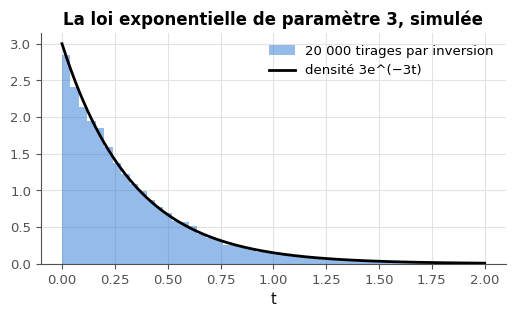

In [24]:
with checked("M02b.20 figure"):
    draws = mymath.distributions.inverse_transform_sample(lambda u: -math.log(1 - u) / 3, 20_000)
    grid_20 = np.linspace(0, 2, 200)
    fig, ax = plt.subplots(figsize=(6, 3))
    ax.hist(draws, bins=np.linspace(0, 2, 51), density=True, alpha=0.5, label="20 000 tirages par inversion")
    ax.plot(grid_20, 3 * np.exp(-3 * grid_20), color="black", label="densité 3e^(−3t)")
    ax.set(xlabel="t", title="La loi exponentielle de paramètre 3, simulée")
    ax.legend()
    plt.show()

💡 b) 0,3328 pour $\frac{1}{3}$ ; c) 4 995 tirages au-delà de 1 pour $100\,000\,e^{-3} \approx 4\,979$ ; f) 0,200 : l'aléa de 100 000 ou 50 000 tirages est de l'ordre de quelques millièmes. Pour la loi géométrique : $\ln(1 - p) < 0$, donc $\frac{\ln(1 - U)}{\ln(1 - p)} > k$ équivaut à $\ln(1 - U) < k\ln(1 - p)$, soit $1 - U < (1 - p)^k$, de probabilité $(1 - p)^k$ car $1 - U$ est uniforme : c'est $P(X > k)$ de la fiche §2.

### Ex M02b.21 — `scipy.stats` : pmf, pdf, cdf, ppf et rvs 📦 ★ ⏱️ 15 min
**Objectif :** utiliser les lois de `scipy.stats` et leurs méthodes, en évitant les pièges de leurs paramètres `loc` et `scale`.  
**Prérequis :** fiche §2, §3 et §8 · **Parcours :** C, E

Chaque loi de `scipy.stats` est un objet qu'on « fige » avec ses paramètres, puis qu'on interroge : `law = stats.binom(10, 0.3)`, puis `law.pmf(k)` (loi discrète), `law.pdf(x)` (densité), `law.cdf(x)` (fonction de répartition), `law.ppf(q)` (la fonction quantile, $F^{-1}$), `law.mean()`, `law.var()`, et `law.rvs(size=..., random_state=...)` pour tirer des valeurs. Les lois continues ont deux paramètres communs, `loc` (un décalage) et `scale` (un facteur d'échelle) : lis `help(stats.expon)` et `help(stats.uniform)` avant e) et h).

Calcule :
- a) $P(X = 3)$ pour $X \sim \mathcal{B}(20 ; 0{,}15)$ (4 décimales) ;
- b) $P(X \le 2)$ pour $X \sim \mathcal{P}(4{,}5)$ (4 décimales) ;
- c) $P(X \le 130)$ pour $X \sim \mathcal{N}(100, 15^2)$ (4 décimales) ;
- d) le percentile 90 de $\mathcal{N}(100, 15^2)$ (2 décimales) ;
- e) l'espérance de la loi exponentielle de **paramètre** $\lambda = 2$, avec `stats.expon` (1 décimale) ;
- f) le nombre $z$ tel que $\Phi(z) = 0{,}975$ (4 décimales) ;
- g) la moyenne de 10 000 tirages de $\mathcal{P}(4{,}5)$, avec `random_state=0` (4 décimales) ;
- h) la variance de la loi uniforme sur $[2 ; 8]$, avec `stats.uniform` (1 décimale).

Dans ta copie : quelle formule de la fiche donne e) et h) ? Que vaudrait d) avec la table de $\Phi$ (indication : $\Phi(1{,}2816) \approx 0{,}9$) ?

In [25]:
answer_M02b_21a = stats.binom(20, 0.15).pmf(3)
answer_M02b_21b = stats.poisson(4.5).cdf(2)
answer_M02b_21c = stats.norm(100, 15).cdf(130)
answer_M02b_21d = stats.norm(100, 15).ppf(0.9)
answer_M02b_21e = stats.expon(scale=1 / 2).mean()          # scale = 1/λ ; stats.expon(2) would shift the law by 2
answer_M02b_21f = stats.norm().ppf(0.975)
answer_M02b_21g = stats.poisson(4.5).rvs(size=10_000, random_state=0).mean()
answer_M02b_21h = stats.uniform(loc=2, scale=6).var()      # [loc ; loc + scale] = [2 ; 8]
print([round(float(v), 4) for v in [answer_M02b_21a, answer_M02b_21b, answer_M02b_21c, answer_M02b_21d,
                                     answer_M02b_21e, answer_M02b_21f, answer_M02b_21g, answer_M02b_21h]])
print("stats.expon(2).mean() =", stats.expon(2).mean(), "· stats.uniform(2, 8).var() =", stats.uniform(2, 8).var())

[0.2428, 0.1736, 0.9772, 119.2233, 0.5, 1.96, 4.4493, 3.0]
stats.expon(2).mean() = 3.0 · stats.uniform(2, 8).var() = 5.333333333333333


In [26]:
wbm.record("M02b.21a", 0.242828896, decimals=4,
           mistakes={"pmf(3) donne P(X = 3) ; cdf(3) donnerait P(X ≤ 3)": 0.647725174})
wbm.record("M02b.21b", 0.173578071, decimals=4,
           mistakes={"cdf(2) = P(X ≤ 2) ; pmf(2) donne seulement P(X = 2)": 0.112478590})
wbm.record("M02b.21c", 0.977249868, decimals=4,
           mistakes={"stats.norm(loc, scale) attend l'écart-type 15, pas la variance 225": 0.553035117})
wbm.record("M02b.21d", 119.223273483, decimals=2,
           mistakes={"le percentile 90 est ppf(0.9), une valeur de X ; cdf donne une probabilité": 1.0,
                     "stats.norm(loc, scale) attend l'écart-type 15, pas la variance 225": 388.349102})
wbm.record("M02b.21e", 0.5, decimals=1,
           mistakes={"stats.expon(2) fixe loc = 2, un décalage ; le paramètre λ se donne par scale = 1/λ": 3.0,
                     "scale = 1/λ, l'inverse du paramètre": 2.0})
wbm.record("M02b.21f", 1.959963985, decimals=4,
           mistakes={"ppf est la réciproque de cdf : ppf(0.975), pas cdf(0.975)": 0.835219870})
wbm.record("M02b.21g", 4.4493, decimals=4)
wbm.record("M02b.21h", 3.0, decimals=1,
           mistakes={"stats.uniform(loc, scale) couvre [loc ; loc + scale] : scale est la largeur de l'intervalle":
                         5.333333})

WBM_ANSWER {"coarse_any": {"1": ["20f8960a60339798c9734209f12597b1c00cd0f069459d823b7554675cfcf88d"]}, "coarser": {"2": ["7f6fcd0744bc11fd28404630130c65264c387c20f0766f088c4863e762ae91cf"]}, "decimals": 4, "hash": "ae26e69202887f11dafd6c0edd536694d2a676288c23b53ff4f9da6f26e0518c", "hash_coarse": "da1581d31c472db530a0a61ca441af78be51e56710bbdc87a46afc9aebdea3c3", "id": "M02b.21a", "kind": "float", "magnitude": -1, "mistakes": {"c6fe14da045c195933438550d64e4c3342f7e69ffbbe72646c96d0a0dd4337b4": "pmf(3) donne P(X = 3) ; cdf(3) donnerait P(X ≤ 3)"}, "sign": 1}
📝 Ex M02b.21a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"1": ["99acbd2482c8dfcdc85dece60b2960e93c5524eaaf8142fd20cb414e9360a1fd"]}, "coarser": {"2": ["a2eb7231cb88711e150e2de1132e72f683b8379ea2983bd882904ef46a01f9f9"]}, "decimals": 4, "hash": "acc6e5ce5f2e22c63eb6659e3c4f0991757b030cfbf939136f65da11c259911a", "hash_coarse": "1787c3e0b6a8ba3ff5343b5edaaf903eb3691473c0398aa273945752a11efcd6", "id": "M02b.21

💡 e) $\frac{1}{\lambda} = 0{,}5$ et h) $\frac{(8 - 2)^2}{12} = 3$ (le tableau de la fiche §4). Les deux pièges de `scipy.stats` : `stats.expon(2)` décale la loi de 2 (espérance 3) ; `stats.uniform(2, 8)` couvre $[2 ; 10]$ (variance $\frac{64}{12}$). d) avec la table : $100 + 1{,}2816 \times 15 \approx 119{,}22$.

## Partie B · Une prédiction, une expérience et une figure

Fiche §2, §5 et §6. La variance d'une moyenne, la vitesse de l'approximation de Poisson, une loi jointe en carte de chaleur.

### Ex M02b.22 — Prédire : la variance de la moyenne de quatre dés 🔮 ★ ⏱️ 10 min
**Objectif :** prévoir l'effet d'une somme et d'une moyenne de variables indépendantes sur la variance et l'écart-type, puis le vérifier par simulation.  
**Prérequis :** fiche §6 · **Parcours :** C, E

On lance quatre dés équilibrés à 8 faces (numérotées de 1 à 8), indépendants. Pour chaque question, choisis : (1) la même ; (2) multipliée (ou divisée) par 2 ; (3) multipliée (ou divisée) par 4 ; (4) multipliée (ou divisée) par 16.
- a) la variance de la **moyenne** des quatre dés, comparée à la variance d'un dé ;
- b) l'écart-type de cette moyenne, comparé à l'écart-type d'un dé ;
- c) la variance de la **somme** des quatre dés, comparée à la variance d'un dé ;
- d) la variance de **4 fois** le résultat d'un seul dé, comparée à la variance d'un dé.

**Avant d'exécuter quoi que ce soit**, écris tes quatre prédictions (le **numéro du choix**, de 1 à 4), vérifie-les, puis lance l'expérience : 100 000 lancers de quatre dés.

In [27]:
wbm.record("M02b.22a", 3, prediction=True, choices=[1, 2, 3, 4])
wbm.record("M02b.22b", 2, prediction=True, choices=[1, 2, 3, 4])
wbm.record("M02b.22c", 3, prediction=True, choices=[1, 2, 3, 4])
wbm.record("M02b.22d", 4, prediction=True, choices=[1, 2, 3, 4])

WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "e7258bc7ff0048bbcf952d9c0e44578347aaa5652d327fe2a8608638e151029c", "id": "M02b.22a", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M02b.22a : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "8a6d73f7fa5d1b3d7bd261443d9fbbb48cd124d00120e0d529d817a931327129", "id": "M02b.22b", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M02b.22b : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "b4cca09876958515a643615c43445c37b2ad1798d6d6543f479b6ff2c2a036d9", "id": "M02b.22c", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M02b.22c : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "7d49867f7a5c2c46ec58da031dfc64ac93b0212a6fb6444e847e3177abb73d51", "id": "M02b.22d", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M02b.22d : réponse enregistrée (int).


**L'expérience.** Elle ne s'exécute qu'une fois tes quatre prédictions écrites.

In [28]:
rng_22 = np.random.default_rng(0)
dice = rng_22.integers(1, 9, size=(100_000, 4))          # 100 000 rows of 4 eight-sided dice
one = dice[:, 0]
print(f"variance d'un dé                        : {one.var():.3f}")
print(f"variance de la moyenne des 4 dés         : {dice.mean(axis=1).var():.3f}")
print(f"écart-type d'un dé / celui de la moyenne : {one.std() / dice.mean(axis=1).std():.2f}")
print(f"variance de la somme des 4 dés           : {dice.sum(axis=1).var():.3f}")
print(f"variance de 4 fois un seul dé            : {(4 * one).var():.3f}")

variance d'un dé                        : 5.241
variance de la moyenne des 4 dés         : 1.310
écart-type d'un dé / celui de la moyenne : 2.00
variance de la somme des 4 dés           : 20.964
variance de 4 fois un seul dé            : 83.855


**Après l'expérience**, dans ta copie : écris les quatre résultats avec les formules de la fiche §6 ($\mathbb{V}(X_1 + \cdots + X_n)$, $\mathbb{V}(aX)$, $\mathbb{V}(\bar{X})$). Pourquoi c) et d) diffèrent-ils, alors que la somme de quatre dés et 4 fois un dé ont la même espérance ?

💡 Un dé à 8 faces a pour variance $\frac{8^2 - 1}{12} = 5{,}25$ (la loi uniforme sur $\{1, \ldots, n\}$ a pour variance $\frac{n^2 - 1}{12}$). a) La moyenne de 4 dés indépendants a pour variance $\frac{5{,}25}{4} \approx 1{,}31$ : divisée par 4 ; b) son écart-type est donc divisé par $\sqrt{4} = 2$. c) La somme a pour variance $4 \times 5{,}25$ : multipliée par 4 (les variances s'additionnent). d) $4X$ a pour variance $16 \times 5{,}25$ : multipliée par 16. Quatre dés différents se compensent en partie ; un seul dé multiplié par 4 amplifie chaque écart, sans compensation.

### Ex M02b.23 — Binomiale et Poisson côte à côte quand n grandit 🔬 ★★ ⏱️ 20 min
**Objectif :** mesurer l'écart entre la loi binomiale $\mathcal{B}(n, \frac{\lambda}{n})$ et la loi de Poisson, et trouver à quelle vitesse il diminue.  
**Prérequis :** fiche §2 ; Ex M02b.13 (la limite) · **Parcours :** C

Pour chaque $n$ de `N_LIST`, on compare la loi binomiale $\mathcal{B}\big(n, \frac{3}{n}\big)$ et la loi de Poisson $\mathcal{P}(3)$ (cellule fournie : `N_LIST`, `LAM` $= 3$). L'**écart** entre les deux est le plus grand des écarts entre leurs probabilités, $\max_{0 \le k \le n} \big\lvert P(B = k) - P(N = k) \big\rvert$. Calcule-le avec `scipy.stats` (`stats.binom(n, p).pmf(ks)` et `stats.poisson(LAM).pmf(ks)` acceptent un array `ks = np.arange(n + 1)`), dans une liste `gaps`, dans l'ordre de `N_LIST`.

Puis :
- a) l'écart pour $n = 10$ (4 décimales) ;
- b) l'écart pour $n = 1\,000$ (5 décimales) ;
- c) le rapport de l'écart pour $n = 100$ à l'écart pour $n = 1\,000$ (1 décimale) ;
- d) le plus petit $n$ de `N_LIST` pour lequel l'écart est inférieur à 0,01 (un entier).

Trace ensuite les écarts en fonction de $n$, en échelles logarithmiques sur les deux axes (`ax.loglog`).

Dans ta copie : quelle pente lis-tu sur ta courbe ? Que dit c) de la vitesse de convergence ? D'après b), à partir de quel $n$ l'approximation de Poisson te semble-t-elle suffisante pour calculer une probabilité à 2 décimales ?

In [29]:
N_LIST = [5, 10, 30, 100, 1000]
LAM = 3

In [30]:
def gap(n):
    ks = np.arange(n + 1)
    return float(np.max(np.abs(stats.binom(n, LAM / n).pmf(ks) - stats.poisson(LAM).pmf(ks))))


gaps = [gap(n) for n in N_LIST]
gap_10, gap_1000 = gaps[1], gaps[4]
ratio_100_1000 = gaps[3] / gaps[4]
first_n = next(n for n, g in zip(N_LIST, gaps) if g < 0.01)
print([f"{g:.2e}" for g in gaps], " c)", round(ratio_100_1000, 1), " d)", first_n)

['1.22e-01', '4.28e-02', '1.20e-02', '3.43e-03', '3.37e-04']  c) 10.2  d) 100


In [31]:
wbm.record("M02b.23a", 0.042786124, decimals=4)
wbm.record("M02b.23b", 0.000336764, decimals=5)
wbm.record("M02b.23c", 10.192, decimals=1,
           mistakes={"l'écart pour n = 100 divisé par l'écart pour n = 1 000, dans cet ordre": 0.098})
wbm.record("M02b.23d", 100,
           mistakes={"compare chaque écart à 0,01 : pour n = 30, il est encore au-dessus": 30})

WBM_ANSWER {"coarse_any": {"2": ["193119bdea58e9f00961cf68625a379bf5b051a4ed5b6b468e81a5c0b721ba35"]}, "decimals": 4, "hash": "203bffd268c2342ca676ca31d20645771c3a9eb81f8e60f7ed81d8d11b32c3e0", "hash_coarse": "697978a8ab5ec4848a70b52f75ab12461ea2d82d4c044038dd43b3bd7995f058", "id": "M02b.23a", "kind": "float", "magnitude": -2, "sign": 1}
📝 Ex M02b.23a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"decimals": 5, "hash": "8a0514ed9579728bb8f0a82db2e2f08c0325b244fdb3ca8aec170e6ed619d83e", "hash_coarse": "4281130bdbfe8b2fb0ed3881c9d8e8819d7e6f2b1c93cbe113c4f32642db342e", "id": "M02b.23b", "kind": "float", "magnitude": -4, "sign": 1}
📝 Ex M02b.23b : réponse enregistrée (float, 5 décimales).
WBM_ANSWER {"decimals": 1, "hash": "24fc088cc0ed2269dac1d80669ff524355e90b461bfee9e574e5331a8b31744a", "hash_coarse": "29e10b6f9e343c0aedb98cbfd1c386a886c474cd1b214d49b9ab58f194c7b8cb", "id": "M02b.23c", "kind": "float", "magnitude": 1, "mistakes": {"fcc80906cfb070150ae0d5ce712687227505d69a7a12

**Le tracé** des écarts en fonction de $n$, en échelles logarithmiques (`ax.loglog`).

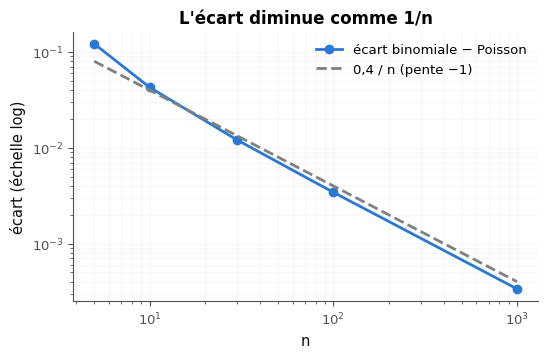

In [32]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.loglog(N_LIST, gaps, marker="o", label="écart binomiale − Poisson")
ax.loglog(N_LIST, [0.4 / n for n in N_LIST], "--", color="gray", label="0,4 / n (pente −1)")
ax.set(xlabel="n", ylabel="écart (échelle log)", title="L'écart diminue comme 1/n")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.show()

💡 L'écart vaut environ 0,12 ; 0,043 ; 0,012 ; 0,0034 ; 0,00034 : il est divisé par 10 quand $n$ est multiplié par 10, une pente de $-1$ en échelles logarithmiques. L'écart diminue comme $\frac{1}{n}$, c'est-à-dire comme $p$ : la loi de Poisson est une bonne approximation quand $p$ est petit, quel que soit $n$ (un théorème dit que l'écart est au plus de l'ordre de $p$). Pour 2 décimales, $n = 100$ ($p = 0{,}03$) suffit déjà largement.

### Ex M02b.24 — Une loi jointe en carte de chaleur, ses marginales sur les bords 🎨 ★ ⏱️ 20 min
**Objectif :** représenter une loi jointe discrète par une carte de chaleur, avec ses deux lois marginales sur les bords, et mesurer l'écart à l'indépendance.  
**Prérequis :** fiche §5 ; R0 (matplotlib) · **Parcours :** C

On lance deux dés équilibrés ; $X$ est le plus petit des deux numéros, et $Y$ le plus grand (le même s'ils sont égaux). La cellule fournie construit leur loi jointe `JOINT_24` (un array 6 × 6 : la ligne $i$ correspond à $X = i + 1$, la colonne $j$ à $Y = j + 1$) et une fonction `joint_axes()` qui prépare une figure à trois axes.

Complète :
- `marginals(joint)`, qui renvoie le couple `(p_rows, p_cols)` des deux lois marginales : celle de la variable des lignes (somme de chaque ligne, `axis=1`) et celle de la variable des colonnes (`axis=0`) ;
- `draw_joint(ax, ax_top, ax_right, joint)`, qui dessine dans `ax` la carte de chaleur `ax.imshow(joint.T, origin="lower", cmap="Blues")` (la variable des lignes à l'horizontale), dans `ax_top` les barres de `p_rows` (`ax_top.bar`), et dans `ax_right` les barres horizontales de `p_cols` (`ax_right.barh`).

Puis calcule `max_gap_24`, le plus grand écart $\big\lvert P(X = x, Y = y) - P(X = x)\,P(Y = y) \big\rvert$ sur les 36 cases (`np.outer` fabrique le tableau des produits ; 4 décimales).

Dans ta copie : pourquoi la moitié de la carte est-elle vide ? Pourquoi la diagonale est-elle plus claire que les cases au-dessus ? $X$ et $Y$ sont-elles indépendantes ? Quelle case le montre le plus nettement, sans aucun calcul ?

In [33]:
# The joint law of (the smaller, the larger) of two fair dice: rows = min (1 to 6), columns = max (1 to 6)
JOINT_24 = np.zeros((6, 6))
for a in range(1, 7):
    for b in range(1, 7):
        JOINT_24[min(a, b) - 1, max(a, b) - 1] += 1 / 36


def joint_axes():
    """A figure with three axes: the heat map, the margin of the rows above it, the margin of the columns on its
    right."""
    fig = plt.figure(figsize=(6.5, 5))
    grid = fig.add_gridspec(2, 2, width_ratios=(4, 1.3), height_ratios=(1.3, 4), wspace=0.08, hspace=0.08)
    ax = fig.add_subplot(grid[1, 0])
    return fig, ax, fig.add_subplot(grid[0, 0], sharex=ax), fig.add_subplot(grid[1, 1], sharey=ax)

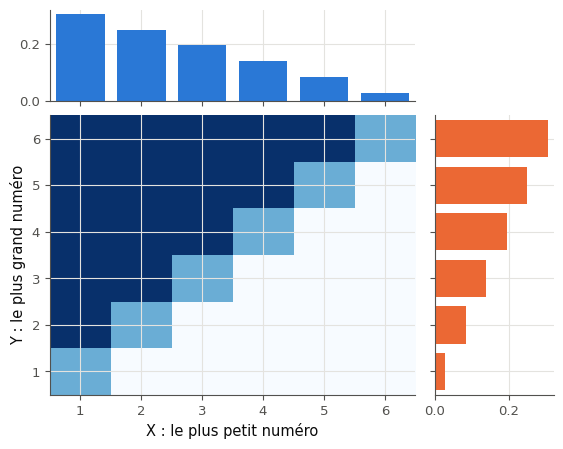

P(X = x) × 36: [11.  9.  7.  5.  3.  1.] · P(Y = y) × 36: [ 1.  3.  5.  7.  9. 11.] · max gap: 0.0378


In [34]:
def marginals(joint):
    """The two margins (p_rows, p_cols) of a discrete joint law given as a 2D array."""
    joint = np.asarray(joint, dtype=float)
    return joint.sum(axis=1), joint.sum(axis=0)


def draw_joint(ax, ax_top, ax_right, joint):
    """Draw the heat map of joint in ax, the margin of the rows above (ax_top), the margin of the columns on the
    right (ax_right)."""
    p_rows, p_cols = marginals(joint)
    ax.imshow(np.asarray(joint).T, origin="lower", cmap="Blues", aspect="auto")
    ax_top.bar(np.arange(len(p_rows)), p_rows, color="C0")
    ax_top.tick_params(labelbottom=False)
    ax_right.barh(np.arange(len(p_cols)), p_cols, color="C1")
    ax_right.tick_params(labelleft=False)


fig, ax, ax_top, ax_right = joint_axes()
draw_joint(ax, ax_top, ax_right, JOINT_24)
ax.set(xlabel="X : le plus petit numéro", ylabel="Y : le plus grand numéro")
ax.set_xticks(range(6), labels=range(1, 7))
ax.set_yticks(range(6), labels=range(1, 7))
plt.show()
p_min, p_max = marginals(JOINT_24)
max_gap_24 = float(np.max(np.abs(JOINT_24 - np.outer(p_min, p_max))))
print("P(X = x) × 36:", np.round(p_min * 36, 6), "· P(Y = y) × 36:", np.round(p_max * 36, 6), "· max gap:",
      round(max_gap_24, 4))

In [35]:
wbm.record("M02b.24", 0.037808642, decimals=4,
           mistakes={"le produit des marginales se calcule case par case : np.outer(p_rows, p_cols)": 0.0})

WBM_ANSWER {"coarse_any": {"2": ["22ca1b10ac7d1a87024f96073d0eb161f04216d26ee035e56071d14623e7d769"]}, "decimals": 4, "hash": "ce5b6ae3f9a5389f3fc1d450388293af1e21da43970dc8b2d42eaf1981a5ae5f", "hash_coarse": "474ce58006987880b557725b4d84bbee4234917f6cd1409ed362fe323a751b6e", "id": "M02b.24", "kind": "float", "magnitude": -2, "mistakes": {"6ec130619c016457eb1d5580600b9b1998c2af584f68596dbea5f49df3818c7c": "le produit des marginales se calcule case par case : np.outer(p_rows, p_cols)"}, "sign": 1}
📝 Ex M02b.24 : réponse enregistrée (float, 4 décimales).


**Vérifications automatiques** (la figure elle-même se juge à l'œil).

In [36]:
with checked("M02b.24 vérifications"):
    problems = []
    test_joint = np.array([[0.1, 0.2, 0.0], [0.05, 0.15, 0.5]])      # 2 rows, 3 columns: a law that is not square
    margins = marginals(test_joint)
    if margins is None:
        problems.append("marginals ne renvoie rien (None) : il manque un return")
    else:
        p_rows, p_cols = (np.asarray(m, dtype=float) for m in margins)
        if p_rows.shape != (2,) or not np.allclose(p_rows, [0.3, 0.7]):
            problems.append("marginals : la loi des lignes somme chaque ligne (sur les colonnes), axis=1")
        if p_cols.shape != (3,) or not np.allclose(p_cols, [0.15, 0.35, 0.5]):
            problems.append("marginals : la loi des colonnes somme chaque colonne (sur les lignes), axis=0")
    fig, ax, ax_top, ax_right = joint_axes()
    try:
        created = drawn(draw_joint, ax, ax_top, ax_right, test_joint)
    finally:
        plt.close(fig)                                   # only the checks below are shown here
    if created:
        problems.append("draw_joint ouvre sa propre figure : dessine dans les trois axes reçus")
    else:
        images = ax.get_images()
        if not images or np.asarray(images[0].get_array()).shape != (3, 2) or not np.allclose(
                np.asarray(images[0].get_array()), test_joint.T):
            problems.append("draw_joint : la carte de chaleur ax.imshow(joint.T, origin=\"lower\"), les valeurs de "
                            "la première variable (les lignes de joint) à l'horizontale")
        top = sorted(round(p.get_height(), 6) for p in ax_top.patches)
        if top != [0.3, 0.7]:
            problems.append("draw_joint : au-dessus, les barres de la loi des lignes (ax_top.bar)")
        right = sorted(round(p.get_width(), 6) for p in ax_right.patches)
        if right != [0.15, 0.35, 0.5]:
            problems.append("draw_joint : à droite, les barres horizontales de la loi des colonnes (ax_right.barh)")
    if problems:
        print("❌ Ex M02b.24 : à revoir : " + " ; ".join(problems) + ".")
    else:
        print("✅ Ex M02b.24 : les marginales, la carte de chaleur et les deux barres des bords.")

✅ Ex M02b.24 : les marginales, la carte de chaleur et les deux barres des bords.


💡 La moitié sous la diagonale est vide : le plus petit numéro ne dépasse jamais le plus grand. Une case de la diagonale vaut $\frac{1}{36}$ (les deux dés égaux : un seul couple), une case au-dessus $\frac{2}{36}$ (deux couples, $(a, b)$ et $(b, a)$). Les marginales valent $\frac{13 - 2x}{36}$ et $\frac{2y - 1}{36}$. Les variables sont dépendantes, et les cases vides le montrent sans calcul : $P(X = 6, Y = 1) = 0$, alors que $P(X = 6)\,P(Y = 1) = \frac{1}{36^2} > 0$. Le plus grand écart, 0,0378, est en $(1, 6)$ : $\frac{2}{36} \approx 0{,}056$ contre $\left(\frac{11}{36}\right)^2 \approx 0{,}093$.

## Partie C · Erreurs classiques, documentation et défi

Fiche §3, §6, §7 et §8. Trois confusions à trouver, une docstring testée, puis des normales fabriquées avec des uniformes.

### Ex M02b.25 — Chasse à l'erreur : une densité prise pour une probabilité, σ et σ² 🐛 ★ ⏱️ 15 min
**Objectif :** repérer trois confusions classiques sur les lois continues, puis calculer les bonnes valeurs.  
**Prérequis :** fiche §3, §4 et §6 · **Parcours :** C

Voici cinq affirmations, chacune avec le raisonnement de son auteur. Trois sont fausses. **Sans exécuter de code**, trouve-les.

- **(A)** « $X \sim \mathcal{N}(0 ;\ 0{,}1^2)$ a pour densité en 0 environ 3,99. C'est impossible, car une probabilité ne dépasse jamais 1 : la formule doit être fausse. »
- **(B)** « $X \sim \mathcal{N}(5, 4)$, donc $P(X \le 7) = \Phi\left(\frac{7 - 5}{4}\right) = \Phi(0{,}5) \approx 0{,}6915$. »
- **(C)** « $X \sim \mathcal{U}([0 ; 4])$ a pour variance $\frac{16}{12} = \frac{4}{3}$, donc pour écart-type $\approx 1{,}1547$. »
- **(D)** « $T \sim \mathcal{E}(2)$, donc $P(T = 1) = f(1) = 2e^{-2} \approx 0{,}2707$. »
- **(E)** « $X$ et $Y$ sont indépendantes, d'écarts-types 3 et 4, donc $\sigma(X + Y) = 5$. »

Questions :
- a) les lettres des affirmations fausses, dans l'ordre alphabétique (un texte) ;
- b) pour chacune des cinq, de (A) à (E), la bonne valeur de la grandeur dont parle son auteur : la densité en 0 pour (A), $P(X \le 7)$ pour (B), l'écart-type pour (C), $P(T = 1)$ pour (D), $\sigma(X + Y)$ pour (E) (une liste de 5 nombres, 4 décimales).

Dans ta copie : pour chaque affirmation fausse, quelle confusion a été faite ? Dans (A), la valeur 3,99 est-elle juste ?

In [37]:
answer_M02b_25a = "ABD"
answer_M02b_25b = [stats.norm(0, 0.1).pdf(0), stats.norm(5, 2).cdf(7), math.sqrt(16 / 12), 0.0, math.sqrt(3 ** 2 + 4 ** 2)]
print(answer_M02b_25a, [round(float(v), 4) for v in answer_M02b_25b])

ABD [3.9894, 0.8413, 1.1547, 0.0, 5.0]


In [38]:
wbm.record("M02b.25a", "ABD",
           mistakes={"il manque une ligne fautive : relis chaque phrase qui compare une densité à 1 : seule l'aire d'une densité doit valoir 1": "BD",
                     "il manque une ligne fautive : relis chaque notation N(μ, ·) : le second paramètre est la variance, et l'on standardise par l'écart-type": "AD",
                     "il manque une ligne fautive : relis chaque probabilité d'une valeur exacte pour une variable à densité": "AB",
                     "une ligne de trop : la ligne (C) est correcte ; relis ce qu'elle fait": "ABCD",
                     "une ligne de trop : la ligne (E) est correcte ; relis ce qu'elle fait": "ABDE",
                     "la ligne (C) est correcte, et il manque une ligne fautive : relis chaque phrase qui compare une densité à 1 : seule l'aire d'une densité doit valoir 1": "BCD",
                     "la ligne (E) est correcte, et il manque une ligne fautive : relis chaque phrase qui compare une densité à 1 : seule l'aire d'une densité doit valoir 1": "BDE",
                     "la ligne (C) est correcte, et il manque une ligne fautive : relis chaque notation N(μ, ·) : le second paramètre est la variance, et l'on standardise par l'écart-type": "ACD",
                     "la ligne (E) est correcte, et il manque une ligne fautive : relis chaque notation N(μ, ·) : le second paramètre est la variance, et l'on standardise par l'écart-type": "ADE",
                     "la ligne (C) est correcte, et il manque une ligne fautive : relis chaque probabilité d'une valeur exacte pour une variable à densité": "ABC",
                     "la ligne (E) est correcte, et il manque une ligne fautive : relis chaque probabilité d'une valeur exacte pour une variable à densité": "ABE",
                     "plusieurs lignes fautives manquent : reprends chaque ligne avec un petit exemple": {"A", "B", "D"},
                     "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple": {"C", "E", "AC", "AE", "BC", "BE", "CD", "CE", "DE", "ACE", "BCE", "CDE", "ABCE", "ACDE", "BCDE"},
                     "plusieurs lignes que tu cites sont correctes : vérifie chacune avec un petit exemple": {"ABCDE"}})
wbm.record("M02b.25b", [3.989422804, 0.841344746, 1.154700538, 0.0, 5.0], decimals=4,
           mistakes={"ce sont les valeurs des auteurs ; donne les bonnes valeurs des grandeurs dont ils parlent":
                         [0.0, 0.691462461, 1.154700538, 0.270670566, 5.0],
                     "(D) : une valeur exacte a une probabilité nulle pour une variable à densité":
                         [3.989422804, 0.841344746, 1.154700538, 0.270670566, 5.0],
                     "(B) : N(5, 4) a pour écart-type 2, et l'on standardise par l'écart-type":
                         [3.989422804, 0.691462461, 1.154700538, 0.0, 5.0],
                     "(A) : la valeur 3,99 de la densité est juste ; c'est le raisonnement qui est faux":
                         [0.0, 0.841344746, 1.154700538, 0.0, 5.0]})

WBM_ANSWER {"hash": "511c5adc9666dc1fc3c7c51fe66052307d2e9f280f8f62ff7e3b682c4f3577cc", "id": "M02b.25a", "kind": "str", "mistakes": {"01ca08ddf10ebd245e92cb19a0bc4766c157eaec658a35b58d649a2ed9fc9924": "plusieurs lignes fautives manquent : reprends chaque ligne avec un petit exemple", "05cd9ac449281f88ebb80d4cb912dfa13e3469fc8bff65d4cd52241c8fda3634": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "06872ae11a128e6ab5e6b9546e3220a42cbc79fb6d8653d8791a0c8be260f23c": "plusieurs lignes fautives manquent : reprends chaque ligne avec un petit exemple", "069659d60f251f952a78e7f7418bf0d3af5088f6203c5635df501c448e98e784": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "06bd85a8def4441b496e9895e0fd72089ef3e88b8f2b5449b81547f312cb853c": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit ex

💡 (A) La valeur est juste ($\frac{1}{0{,}1\sqrt{2\pi}} \approx 3{,}9894$), le raisonnement faux : une densité n'est pas une probabilité, et seule son aire vaut 1. (B) $\mathcal{N}(5, 4)$ a pour variance 4, donc pour écart-type 2 : $\Phi\big(\frac{7 - 5}{2}\big) = \Phi(1) \approx 0{,}8413$. (D) Pour une variable à densité, $P(T = 1) = 0$ ; $f(1)$ est une probabilité par unité de temps. (C) et (E) sont justes : $\sqrt{9 + 16} = 5$.

### Ex M02b.26 — Documenter une loi : docstring et exemples testés (`doctest`) 🛠️ ★ ⏱️ 15 min
**Objectif :** écrire une docstring au format NumPy dont les exemples sont exécutés comme des tests, réflexe professionnel pour une fonction de bibliothèque.  
**Prérequis :** fiche §2 ; les docstrings de `mymath` · **Parcours :** C

Les docstrings de `mymath` suivent le format NumPy (sections `Parameters`, `Returns`, `Raises`, `Examples`), et leurs exemples `>>>` sont des **tests** : le module `doctest` les exécute et compare le résultat affiché à celui qui est écrit. Une documentation testée ne ment pas.

Écris `geometric_pmf(k, p)`, la probabilité $P(X = k) = (1 - p)^{k-1}p$ de la loi géométrique (fiche §2), qui vaut `0.0` pour $k < 1$ et lève une `ValueError` si $p$ n'est pas dans $]0 ; 1]$, **avec sa docstring complète** : les quatre sections, et au moins trois exemples, dont une valeur ordinaire, le cas $k = 0$, et le cas d'erreur. Un exemple qui lève une erreur s'écrit ainsi :

```
>>> geometric_pmf(2, 1.5)
Traceback (most recent call last):
    ...
ValueError: p must be in ]0, 1]
```

(le message après `ValueError:` doit être exactement celui que lève ta fonction). Exécute ensuite tes exemples avec `doctest.run_docstring_examples(geometric_pmf, globals())` : rien ne s'affiche s'ils passent tous.

Dans ta copie : pourquoi un exemple de docstring qui n'est pas testé finit-il souvent par être faux ? Pourquoi écrire `round(..., 4)` dans un exemple qui affiche un flottant ?

In [39]:
def geometric_pmf(k, p):
    """Return ``P(X = k)`` for ``X`` following the geometric law of parameter ``p`` (rank of the first success).

    Parameters
    ----------
    k : int
        Any integer: the probability is 0.0 when ``k < 1``.
    p : float
        Probability of success of each trial, in ``]0, 1]``.

    Returns
    -------
    float
        ``(1 - p)**(k - 1) * p``.

    Raises
    ------
    ValueError
        If ``p`` is not in ``]0, 1]``.

    Examples
    --------
    >>> geometric_pmf(3, 0.5)
    0.125
    >>> geometric_pmf(0, 0.5)
    0.0
    >>> round(geometric_pmf(2, 0.1), 4)
    0.09
    >>> geometric_pmf(2, 1.5)
    Traceback (most recent call last):
        ...
    ValueError: p must be in ]0, 1]
    """
    if not 0 < p <= 1:
        raise ValueError("p must be in ]0, 1]")
    if k < 1:
        return 0.0
    return float((1 - p) ** (k - 1) * p)


import doctest

doctest.run_docstring_examples(geometric_pmf, globals())   # silent: every example passes

In [40]:
with checked("M02b.26 vérifications"):
    import doctest

    problems = []
    doc = geometric_pmf.__doc__ or ""
    for word in ("Parameters", "Returns", "Raises", "Examples"):
        if word not in doc:
            problems.append(f"la docstring n'a pas de section « {word} » (le format NumPy des docstrings de mymath)")
    tests = doctest.DocTestFinder().find(geometric_pmf, "geometric_pmf", globs={"geometric_pmf": geometric_pmf})
    runner = doctest.DocTestRunner(optionflags=doctest.ELLIPSIS)
    for test in tests:
        runner.run(test, out=lambda text: None)
    attempted, failed = runner.tries, runner.failures
    if attempted < 3:
        problems.append(f"la docstring a {attempted} exemple(s) >>> : il en faut au moins 3 (une valeur ordinaire, "
                        "k = 0, et le cas d'erreur)")
    if failed:
        problems.append(f"{failed} exemple(s) de la docstring échoue(nt) : exécute "
                        "doctest.run_docstring_examples(geometric_pmf, globals()) pour les voir")
    if "ValueError" not in doc:
        problems.append("aucun exemple ne montre la ValueError (un exemple peut afficher Traceback ... ValueError)")
    cases = [(1, 0.25), (4, 0.25), (10, 0.6), (3, 1.0)]
    wrong = [(k, p) for k, p in cases if abs(geometric_pmf(k, p) - float(stats.geom(p).pmf(k))) > 1e-12]
    if wrong:
        problems.append(f"geometric_pmf se trompe, par exemple pour (k, p) = {wrong[0]} : (1 − p)^(k − 1) p")
    if geometric_pmf(0, 0.3) != 0.0 or geometric_pmf(-2, 0.3) != 0.0:
        problems.append("geometric_pmf(0, p) et geometric_pmf(-2, p) valent 0.0 : le premier succès a un rang au "
                        "moins égal à 1")
    if raised(geometric_pmf, 2, 0) != "ValueError" or raised(geometric_pmf, 2, 1.5) != "ValueError":
        problems.append("geometric_pmf lève une ValueError si p n'est pas dans ]0 ; 1]")
    if problems:
        print("❌ Ex M02b.26 : à revoir : " + " ; ".join(problems) + ".")
    else:
        print(f"✅ Ex M02b.26 : une docstring complète, {attempted} exemples qui passent, et une fonction juste.")

✅ Ex M02b.26 : une docstring complète, 4 exemples qui passent, et une fonction juste.


💡 Un exemple non testé dérive : on change la fonction, on oublie l'exemple, et la documentation ment. `doctest` compare des **textes** : un flottant affiché avec 17 chiffres (`0.09000000000000001`) ferait échouer l'exemple, d'où `round(..., 4)`, ou une valeur exacte en binaire comme 0,125. Les tests de `mymath` exécutent aussi les exemples des docstrings (le test « docstring example » de chaque fonction).

### Ex M02b.27 — Défi : tirer des valeurs normales avec seulement des tirages uniformes 🏆 ★★★ ⏱️ 30 min
**Objectif :** fabriquer des tirages de la loi normale centrée réduite à partir de nombres uniformes, assez fidèles pour passer un test statistique et reproduire les queues de la loi.  
**Prérequis :** fiche §7 et §8 ; Ex M02b.12 et M02b.20 · **Parcours :** C

Écris `normal_draws(rng, n)`, qui renvoie un array de $n$ tirages de $\mathcal{N}(0, 1)$ en n'utilisant **que** `rng.random(size)` : le générateur `UniformOnly` de la cellule fournie ne sait rien faire d'autre, et la vérification refuse `normal`, `scipy`, `ppf`, `erfinv`, `NormalDist` et un générateur à toi. **Objectifs**, vérifiés sur un million de valeurs :
1. le test de Kolmogorov-Smirnov (`stats.kstest`, qui compare la fonction de répartition des tirages à $\Phi$) ne rejette pas la loi normale : $p > 0{,}01$ sur 200 000 valeurs ;
2. les **queues** sont justes : la part des valeurs au-delà de 4 en valeur absolue est entre $3 \times 10^{-5}$ et $10^{-4}$ (la loi normale donne $2(1 - \Phi(4)) \approx 6{,}3 \times 10^{-5}$) ;
3. moins de 3 secondes pour un million de valeurs.

Pistes, de la plus simple à la plus élégante (`04_indices.md` les détaille) :
- additionner 12 uniformes et retrancher 6 (le théorème central limite) : tente-la, et regarde quel objectif elle manque, et pourquoi ;
- inverser $\Phi$ par dichotomie (M02a.18) : juste, mais lente, car `math.erf` ne traite qu'un nombre à la fois (essaie-la sur 1 000 valeurs) ;
- une transformation de **deux** uniformes en **deux** normales indépendantes, qui vient de l'intégrale de Gauss en coordonnées polaires (M02b.12, question 6 : la loi jointe de deux normales indépendantes ne dépend que de la distance au centre).

Dans ta copie : quelle méthode as-tu retenue, et pourquoi la somme de 12 uniformes échoue-t-elle sur les queues ? Pour la méthode polaire, quelle est la loi de $R^2 = X^2 + Y^2$ ?

In [41]:
class UniformOnly:
    """A generator that can only draw uniform numbers in [0, 1): random(size)."""

    def __init__(self, seed):
        self._rng = np.random.default_rng(seed)

    def random(self, size=None):
        return self._rng.random(size)


FORBIDDEN_27 = ("normal", "standard_normal", "scipy", "ppf", "erfinv", "NormalDist", "default_rng", "Generator")

In [42]:
def normal_draws(rng, n):
    """Return n draws of N(0, 1) as an array of shape (n,), using only rng.random(size): the Box-Muller method."""
    m = (n + 1) // 2
    radius = np.sqrt(-2 * np.log(1 - rng.random(m)))     # R² = −2 ln(1 − U) follows the exponential law of mean 2
    angle = 2 * np.pi * rng.random(m)                     # the angle is uniform on [0, 2π[
    return np.concatenate([radius * np.cos(angle), radius * np.sin(angle)])[:n]


clt = UniformOnly(1).random((1_000_000, 12)).sum(axis=1) - 6       # the first idea: 12 uniforms, minus 6
print(f"12 uniforms: |z| > 4 for a share {np.mean(np.abs(clt) > 4):.1e}, max |z| = {np.abs(clt).max():.2f}")
draws = normal_draws(UniformOnly(2026), 1_000_000)
print(f"Box-Muller: mean {draws.mean():.4f}, std {draws.std():.4f}, |z| > 4 for a share {np.mean(np.abs(draws) > 4):.1e}")

12 uniforms: |z| > 4 for a share 1.4e-05, max |z| = 4.67
Box-Muller: mean -0.0011, std 0.9988, |z| > 4 for a share 6.4e-05


In [43]:
wbm.record("M02b.27", True,
           mistakes={"un objectif au moins n'est pas atteint : relis les lignes ❌ et les pistes de 04_indices.md":
                         False})

WBM_ANSWER {"hash": "c33bcda17b2d09fabfe1e12ab324ad3fd42244e9307d6a3f5c085b21b1ae328c", "id": "M02b.27", "kind": "bool", "mistakes": {"5e416a6775d3148329b4eba6e03bf8b34c7fe08e1d92ad052f07a23f86b1c4d9": "un objectif au moins n'est pas atteint : relis les lignes ❌ et les pistes de 04_indices.md"}}
📝 Ex M02b.27 : réponse enregistrée (bool).


💡 La somme de 12 uniformes a la bonne espérance et la bonne variance, et une forme de cloche presque parfaite au centre, mais elle ne dépasse jamais 6 et ses queues sont bien trop minces : 1 à 2 valeurs sur 100 000 au-delà de 4, au lieu de 6,3. La méthode de **Box-Muller** (1958) tire le carré de la distance au centre, $R^2 = -2\ln(1 - U_1)$, de loi exponentielle d'espérance 2 (fiche §8), et l'angle $\Theta = 2\pi U_2$, uniforme, puis renvoie $R\cos\Theta$ et $R\sin\Theta$ : deux normales indépendantes, exactement, parce que la densité jointe $\frac{1}{2\pi}e^{-r^2/2}$ ne dépend que de $r$ (M02b.12, question 6). L'inversion de $\Phi$ par dichotomie donne des tirages justes, mais un million d'appels à `math.erf` par étape de dichotomie dépasse largement les 3 secondes.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Reconnais-tu la loi d'une situation, et calcules-tu ses probabilités, son espérance et sa variance ?
2. Lis-tu une loi jointe, ses marginales, et sais-tu décider de l'indépendance ?
3. Sais-tu calculer la variance d'une somme ou d'une moyenne, et simuler une loi par inversion ?

**La suite** : M02c, les échantillons et l'estimation (loi des grands nombres, théorème central limite, intervalles de confiance, covariance), puis le chapitre 2 de workbookIA.